# Антифрод-кейс: CPA-мережі

Перевірив 14 партнерських мереж за 01.01-23.07.2026: 3,77 млн реєстрацій і 20,4 млн бюджету CPA. PPC і органіку (ще 4,3 млн реєстрацій) використав як еталон для порівняння.

Фрод знайшов у трьох мережах: 612 - кардинг, 523 - клікери, 911 - мотивований трафік з тимчасових пошт. На фродові сегменти за період пішло 388 224 - 1,9% бюджету CPA.

612 - вимкнути і вимагати повернення 176 258: це єдина мережа, що не окупається (net ROAS 0,85). З 523 і 911, які окупаються, - переговори: не платити за фродові сегменти.

Розділи: 0 - дані та їхня якість; 1-2 - огляд трафіку і модель виплати; 3-7 - сигнали фроду: час до реєстрації, домени й пристрої, chargeback, гео й відмови, залученість; 8 - економіка і рішення по кожній мережі; 9 - CSV для дашборда.

## 0. Дані: завантаження і перевірка якості

In [1]:
# Підготовка: Drive, бібліотеки, допоміжні функції, папка для графіків
!pip install -q duckdb pycountry

import os
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import drive

drive.mount('/content/drive')

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

DATA_DIR = '/content/drive/MyDrive/Case 3'
CHARTS_DIR = f'{DATA_DIR}/charts'
os.makedirs(CHARTS_DIR, exist_ok=True)


def q(sql):
    """Виконує SQL по таблицях у пам'яті (df_registrations, df_payments, df_activity, df_credits) і повертає DataFrame."""
    return duckdb.query(sql).df()


def save(fig, name):
    """Зберігає графік у Case 3/charts"""
    fig.savefig(f'{CHARTS_DIR}/{name}.png', dpi=150, bbox_inches='tight')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### завантаження, структура таблиць, дублі

In [2]:
!pip install duckdb -q


import duckdb
import os
import pandas as pd
folder_path = '/content/drive/MyDrive/Case 3'

con = duckdb.connect()

con.execute("PRAGMA memory_limit='8GB'")

print("Створення віртуальних таблиць (читання з диска)...")
con.execute(f"CREATE OR REPLACE VIEW registrations AS SELECT * FROM read_csv_auto('{folder_path}/registrations.csv')")
con.execute(f"CREATE OR REPLACE VIEW activity AS SELECT * FROM read_csv_auto('{folder_path}/activity_log.csv')")
con.execute(f"CREATE OR REPLACE VIEW payments AS SELECT * FROM read_csv_auto('{folder_path}/payments.csv')")
con.execute(f"CREATE OR REPLACE VIEW credits AS SELECT * FROM read_csv_auto('{folder_path}/credits.csv')")


print("Топ-5 мереж за кількістю реєстрацій:")
query = """
    SELECT
        network,
        COUNT(id_user) as users_count
    FROM registrations
    GROUP BY network
    ORDER BY users_count DESC
    LIMIT 5
"""

result = con.execute(query).df()
display(result)

Створення віртуальних таблиць (читання з диска)...
Топ-5 мереж за кількістю реєстрацій:


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,network,users_count
0,ppc,3117908
1,organic,1156766
2,833,1114202
3,523,790549
4,911,267478


In [3]:
import gc

try:
    del df_activity, df_credits, df_payments, df_registrations
except NameError:
    pass
gc.collect()

print("2. Дедуплікація через DuckDB (SELECT DISTINCT)")

df_registrations = con.execute("SELECT DISTINCT * FROM registrations").df()
print(f"df_registrations очищено! Рядків: {len(df_registrations)}")

df_payments = con.execute("SELECT DISTINCT * FROM payments").df()
print(f"df_payments очищено! Рядків: {len(df_payments)}")

df_credits = con.execute("SELECT DISTINCT * FROM credits").df()
print(f"df_credits очищено! Рядків: {len(df_credits)}")

print("Обробка 96 млн рядків activity")
df_activity = con.execute("SELECT DISTINCT * FROM activity").df()
print(f"df_activity очищено! Рядків: {len(df_activity)}")

print("Усі таблиці очищено від дублів")

2. Дедуплікація через DuckDB (SELECT DISTINCT)


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

df_registrations очищено! Рядків: 8049602


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

df_payments очищено! Рядків: 2301691


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

df_credits очищено! Рядків: 35560418
Обробка 96 млн рядків activity


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

df_activity очищено! Рядків: 63914103
Усі таблиці очищено від дублів


In [4]:
df_activity.rename(columns={'f0_': 'id_user'}, inplace=True)

In [5]:
df_activity.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 63914103 entries, 0 to 63914102
Data columns (total 3 columns):
 #   Column      Dtype         
---  ------      -----         
 0   id_user     int64         
 1   date_start  datetime64[us]
 2   duration    int64         
dtypes: datetime64[us](1), int64(2)
memory usage: 1.4 GB


In [6]:

query_activity_dupes = """
    SELECT
        (SELECT COUNT(*) FROM activity) -
        (SELECT COUNT(*) FROM (SELECT DISTINCT * FROM activity)) AS exact_duplicates_count
"""

df_act_dupes = con.execute(query_activity_dupes).df()
display(df_act_dupes)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,exact_duplicates_count
0,32389481


In [7]:
df_credits.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35560418 entries, 0 to 35560417
Data columns (total 4 columns):
 #   Column           Dtype         
---  ------           -----         
 0   f0_              int64         
 1   date_created     datetime64[us]
 2   credits_changed  int64         
 3   credit_type      object        
dtypes: datetime64[us](1), int64(2), object(1)
memory usage: 1.1+ GB


In [8]:
df_credits.head()

,f0_,date_created,credits_changed,credit_type
0,144009683,2026-07-08 04:02:09,2,1
1,144179212,2026-06-01 03:43:32,2,1
2,144179212,2026-07-11 19:21:02,2,1
3,144365591,2026-02-27 01:20:36,2,1
4,144455938,2026-01-29 21:11:04,2,1


In [9]:
df_credits.duplicated().sum()

np.int64(0)

In [10]:
df_credits.rename(columns={'f0_': 'id_user'}, inplace=True)

In [11]:
df_payments.head()

,id_user,date_created,amount,status,country_payment,chargeback_date
0,156594113,2026-03-30 07:36:36,45,success,DEU,NaT
1,157362628,2026-03-30 07:37:08,65,fail,CAN,NaT
2,157576639,2026-03-30 07:39:28,500,fail,USA,NaT
3,151442751,2026-03-30 07:39:52,45,success,ITA,NaT
4,149500526,2026-03-30 07:40:24,65,success,NZL,NaT


In [12]:
df_payments.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2301691 entries, 0 to 2301690
Data columns (total 6 columns):
 #   Column           Dtype         
---  ------           -----         
 0   id_user          int64         
 1   date_created     datetime64[us]
 2   amount           Int64         
 3   status           object        
 4   country_payment  object        
 5   chargeback_date  datetime64[us]
dtypes: Int64(1), datetime64[us](2), int64(1), object(2)
memory usage: 107.6+ MB


In [13]:
df_payments.duplicated().sum()

np.int64(0)

In [14]:
df_activity.head()

,id_user,date_start,duration
0,150370141,2026-02-19 15:03:47.239557,354
1,150661822,2026-02-25 20:30:00.020029,110
2,150653415,2026-04-08 09:20:33.255883,152
3,149828666,2026-02-16 08:47:14.976763,144
4,150374240,2026-04-19 13:45:59.000000,361


In [15]:
df_registrations.head()

,id_user,id_metauser,email,date_created,date_visit,network,traffic_type,country,device_os,user_agent,cost
0,173983827,1852660774,1dffc385@gmail.com,2026-06-22 11:07:53,2026-06-22 11:02:20.147404,ppc,ppc,MG,Android,mozilla/5.0 (linux; android 10; k) applewebkit...,2.1904
1,173985959,1671387119,5e59ce2c@gmail.com,2026-06-22 11:25:37,2026-06-22 11:23:12.261346,ppc,ppc,RS,Android,mozilla/5.0 (linux; android 16; 25100ra69g bui...,0.5624
2,173992911,209117688,ac5f8353@gmail.com,2026-06-22 12:23:31,2026-06-22 12:20:53.399612,833,cpa,CA,Android,None,NaN
3,173993796,1852944962,859e25f3@hotmail.com,2026-06-22 12:30:53,2026-06-22 12:26:04.213757,ppc,ppc,EC,Android,mozilla/5.0 (linux; android 10; k) applewebkit...,3.5668
4,174002405,1853174896,b6f5726f@gmail.com,2026-06-22 13:33:04,2026-06-22 13:31:31.792382,ppc,ppc,CY,iOS,mozilla/5.0 (iphone; cpu iphone os 26_1_0 like...,2.1978


In [16]:
df_registrations.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8049602 entries, 0 to 8049601
Data columns (total 11 columns):
 #   Column        Dtype         
---  ------        -----         
 0   id_user       int64         
 1   id_metauser   Int64         
 2   email         object        
 3   date_created  datetime64[us]
 4   date_visit    datetime64[us]
 5   network       object        
 6   traffic_type  object        
 7   country       object        
 8   device_os     object        
 9   user_agent    object        
 10  cost          float64       
dtypes: Int64(1), datetime64[us](2), float64(1), int64(1), object(6)
memory usage: 683.2+ MB


In [17]:
df_registrations.duplicated().sum()

np.int64(0)

### дублі в сирих файлах

In [18]:
# Дублі в сирих файлах
# Вище дублі рахувались уже після DISTINCT, тому виходив 0. Тут порівнюємо сирі файли з очищеними таблицями
for name, df in [('registrations', df_registrations), ('payments', df_payments),
                 ('credits', df_credits), ('activity', df_activity)]:
    raw = con.execute(f'SELECT COUNT(*) FROM {name}').fetchone()[0]
    dup = raw - len(df)
    print(f'{name:<14} сирих: {raw:>12,}   після DISTINCT: {len(df):>12,}   дублів: {dup:>11,} ({dup / raw:.2%})')

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

registrations  сирих:    8,049,602   після DISTINCT:    8,049,602   дублів:           0 (0.00%)
payments       сирих:    2,301,720   після DISTINCT:    2,301,691   дублів:          29 (0.00%)


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

credits        сирих:   35,658,710   після DISTINCT:   35,560,418   дублів:      98,292 (0.28%)


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

activity       сирих:   96,303,584   після DISTINCT:   63,914,103   дублів:  32,389,481 (33.63%)


### пропуски, суми платежів, зв'язки між таблицями, «подорожі в часі»


In [19]:
orphan_payers = set(df_payments['id_user']) - set(df_registrations['id_user'])
print(f"Платники без реєстрацій: {len(orphan_payers)}")

Платники без реєстрацій: 0


In [20]:
for name, df in [
    ('payments', df_payments),
    ('registrations',      df_registrations),
    ('activity',      df_activity),
    ('credits',    df_credits),
]:
    nulls = df.isna().sum()
    total = nulls.sum()
    print(f"--- {name} ({total} пропусків) ---")
    if total > 0:
        print(nulls[nulls > 0].to_string())
    else:
        print("пропусків немає")
    print()

--- payments (2424240 пропусків) ---
amount                3088
country_payment     127386
chargeback_date    2293766

--- registrations (8371524 пропусків) ---
id_metauser      15404
country           1561
user_agent     4918274
cost           3436285

--- activity (0 пропусків) ---
пропусків немає

--- credits (0 пропусків) ---
пропусків немає



In [21]:
query_nulls = """
    SELECT
        network,
        COUNT(id_user) AS total_users,
        SUM(CASE WHEN device_OS IS NULL THEN 1 ELSE 0 END) AS missing_os,
        SUM(CASE WHEN user_agent IS NULL THEN 1 ELSE 0 END) AS missing_ua,
        SUM(CASE WHEN country IS NULL THEN 1 ELSE 0 END) AS missing_country
    FROM df_registrations
    GROUP BY network
    ORDER BY total_users DESC
"""
df_nulls_check = con.execute(query_nulls).df()
display(df_nulls_check.head(10))

,network,total_users,missing_os,missing_ua,missing_country
0,ppc,3117908,0.0,1891.0,366.0
1,organic,1156766,0.0,1141455.0,881.0
2,833,1114202,0.0,1114202.0,19.0
3,523,790549,0.0,790549.0,87.0
4,911,267478,0.0,267478.0,19.0
5,427,232251,0.0,232251.0,10.0
6,851,219451,0.0,219451.0,66.0
7,413,184394,0.0,184394.0,1.0
8,303,174637,0.0,174637.0,9.0
9,897,153366,0.0,153366.0,6.0


In [22]:
con.execute(
    """
    SELECT COUNT(DISTINCT amount)
    FROM df_payments
    """
).df()

,count(DISTINCT amount)
0,39


In [23]:
con.execute(
    """
    SELECT amount, COUNT(*)
    FROM df_payments
    GROUP BY amount
    ORDER BY COUNT(*) DESC
    """
).df()

,amount,count_star()
0,45,788009
1,125,401128
2,65,356666
3,800,176896
4,270,159005
5,150,152516
6,100,71439
7,40,38695
8,30,37488
9,2000,36922


In [24]:
query_grain = """
    SELECT
        COUNT(*) AS total_rows,
        COUNT(DISTINCT id_user) AS unique_users,
        COUNT(*) - COUNT(DISTINCT id_user) AS potential_fan_out_risk
    FROM df_registrations
"""
display(duckdb.query(query_grain).df())

,total_rows,unique_users,potential_fan_out_risk
0,8049602,8049602,0


In [25]:
len(df_activity[df_activity['duration'] <=0])

0

In [26]:
len(df_activity[df_activity['duration'] >=1000])

1760231

In [27]:
query_orphans = """
    SELECT
        'activity_log' AS source_table,
        COUNT(a.id_user) AS total_events,
        SUM(CASE WHEN r.id_user IS NULL THEN 1 ELSE 0 END) AS orphaned_events
    FROM df_activity a
    LEFT JOIN df_registrations r ON a.id_user = r.id_user

    UNION ALL

    SELECT
        'payments' AS source_table,
        COUNT(p.id_user) AS total_events,
        SUM(CASE WHEN r.id_user IS NULL THEN 1 ELSE 0 END) AS orphaned_events
    FROM df_payments p
    LEFT JOIN df_registrations r ON p.id_user = r.id_user

    UNION ALL

    SELECT
        'credits' AS source_table,
        COUNT(c.id_user) AS total_events,
        SUM(CASE WHEN r.id_user IS NULL THEN 1 ELSE 0 END) AS orphaned_events
    FROM df_credits c
    LEFT JOIN df_registrations r ON c.id_user = r.id_user
"""

print("Перевіряємо наявність 'осиротілих' подій через змінні Pandas...")

df_orphans = duckdb.query(query_orphans).df()

df_orphans['orphaned_percentage'] = (df_orphans['orphaned_events'] / df_orphans['total_events']) * 100

display(df_orphans)

Перевіряємо наявність 'осиротілих' подій через змінні Pandas...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,source_table,total_events,orphaned_events,orphaned_percentage
0,activity_log,63914103,2173.0,0.0034
1,payments,2301691,0.0,0.0000
2,credits,35560418,0.0,0.0000


In [28]:
query_time_travel_rate = """
    SELECT
        r.network,
        COUNT(a.id_user) AS total_sessions,
        SUM(CASE WHEN CAST(a.date_start AS TIMESTAMP) < CAST(r.date_created AS TIMESTAMP) THEN 1 ELSE 0 END) AS time_travel_sessions,
        ROUND(SUM(CASE WHEN CAST(a.date_start AS TIMESTAMP) < CAST(r.date_created AS TIMESTAMP) THEN 1 ELSE 0 END) * 100.0 / COUNT(a.id_user), 6) AS time_travel_rate_pct
    FROM df_activity a
    JOIN df_registrations r ON a.id_user = r.id_user
    GROUP BY r.network
    HAVING time_travel_sessions > 0
    ORDER BY time_travel_rate_pct DESC
"""
display(duckdb.query(query_time_travel_rate).df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,network,total_sessions,time_travel_sessions,time_travel_rate_pct
0,523,1476848,9.0,0.000609
1,911,289251,1.0,0.000346
2,833,3797706,8.0,0.000211
3,303,665410,1.0,0.000150
4,427,2166579,3.0,0.000138
5,1052,774270,1.0,0.000129
6,897,1745548,2.0,0.000115
7,organic,12058481,11.0,0.000091
8,ppc,32846284,25.0,0.000076
9,612,1362450,1.0,0.000073


In [29]:
query_time_travel_payments = """
    SELECT
        COALESCE(r.network, 'ORPHAN_PAYMENT') AS network,
        COUNT(p.id_user) AS total_payments,
        SUM(CASE
            WHEN r.id_user IS NULL THEN 1 -- Сирота (немає реєстрації взагалі)
            WHEN CAST(p.date_created AS TIMESTAMP) < CAST(r.date_created AS TIMESTAMP) THEN 1 -- Time travel
            ELSE 0
        END) AS fraudulent_payments,
        ROUND(SUM(CASE WHEN r.id_user IS NULL OR CAST(p.date_created AS TIMESTAMP) < CAST(r.date_created AS TIMESTAMP) THEN 1 ELSE 0 END) * 100.0 / COUNT(p.id_user), 2) AS fraud_rate_pct
    FROM df_payments p
    LEFT JOIN df_registrations r ON p.id_user = r.id_user
    GROUP BY COALESCE(r.network, 'ORPHAN_PAYMENT')
    ORDER BY fraud_rate_pct DESC
"""

df_time_travel_pay = duckdb.query(query_time_travel_payments).df()
display(df_time_travel_pay)

,network,total_payments,fraudulent_payments,fraud_rate_pct
0,427,99648,0.0,0.0
1,730,49489,0.0,0.0
2,612,11157,0.0,0.0
3,719,53856,0.0,0.0
4,889,17123,0.0,0.0
5,523,43182,0.0,0.0
6,1052,51540,0.0,0.0
7,303,19377,0.0,0.0
8,organic,441149,0.0,0.0
9,ppc,1173095,0.0,0.0


## 1. Огляд: мережі й обсяг трафіку в часі

### типи трафіку і тижневі тренди підозрілих мереж

In [30]:
query_traffic_type = """
    SELECT
        network,
        traffic_type,
        COUNT(*) AS cnt
    FROM df_registrations
    GROUP BY network, traffic_type
    ORDER BY network, cnt DESC
"""
display(duckdb.query(query_traffic_type).df())

,network,traffic_type,cnt
0,1002,cpa,108535
1,1052,cpa,95788
2,303,cpa,174637
3,413,cpa,184394
4,427,cpa,232251
5,523,cpa,790549
6,612,cpa,111675
7,719,cpa,123232
8,730,cpa,137252
9,833,cpa,1114202


In [31]:
query_weekly_trend = """
    SELECT
        network,
        DATE_TRUNC('week', CAST(date_created AS TIMESTAMP)) AS reg_week,
        COUNT(*) AS weekly_regs
    FROM df_registrations
    WHERE network IN ('612', '851', '911', '303')
    GROUP BY network, DATE_TRUNC('week', CAST(date_created AS TIMESTAMP))
    ORDER BY network, reg_week
"""

df_weekly_trend = duckdb.query(query_weekly_trend).df()
display(df_weekly_trend.head())

,network,reg_week,weekly_regs
0,303,2025-12-29,5179
1,303,2026-01-05,6014
2,303,2026-01-12,1215
3,303,2026-01-19,639
4,303,2026-01-26,990


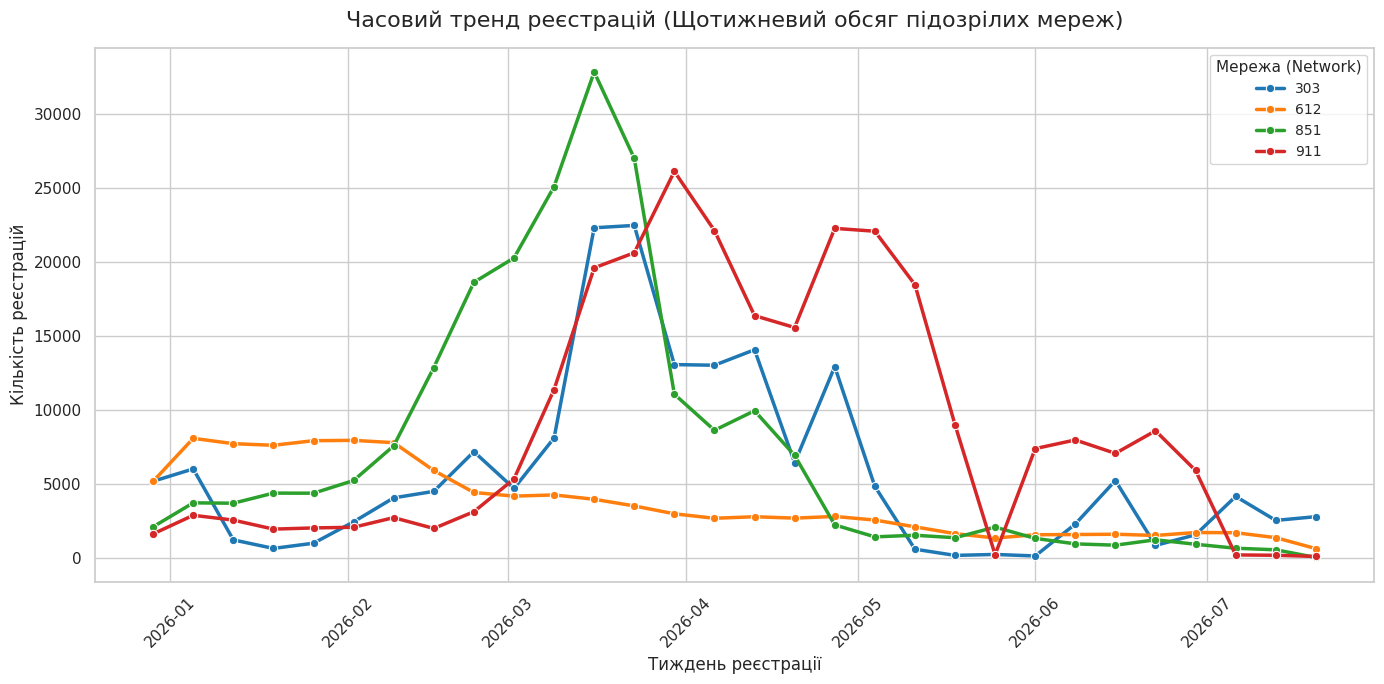

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 7))

sns.lineplot(
    data=df_weekly_trend,
    x='reg_week',
    y='weekly_regs',
    hue='network',
    marker='o',
    linewidth=2.5,
    palette="tab10"
)

plt.title('Часовий тренд реєстрацій (Щотижневий обсяг підозрілих мереж)', fontsize=16, pad=15)
plt.xlabel('Тиждень реєстрації', fontsize=12)
plt.ylabel('Кількість реєстрацій', fontsize=12)
plt.xticks(rotation=45)
plt.legend(title='Мережа (Network)', title_fontsize='11', fontsize='10')
plt.tight_layout()

plt.show()

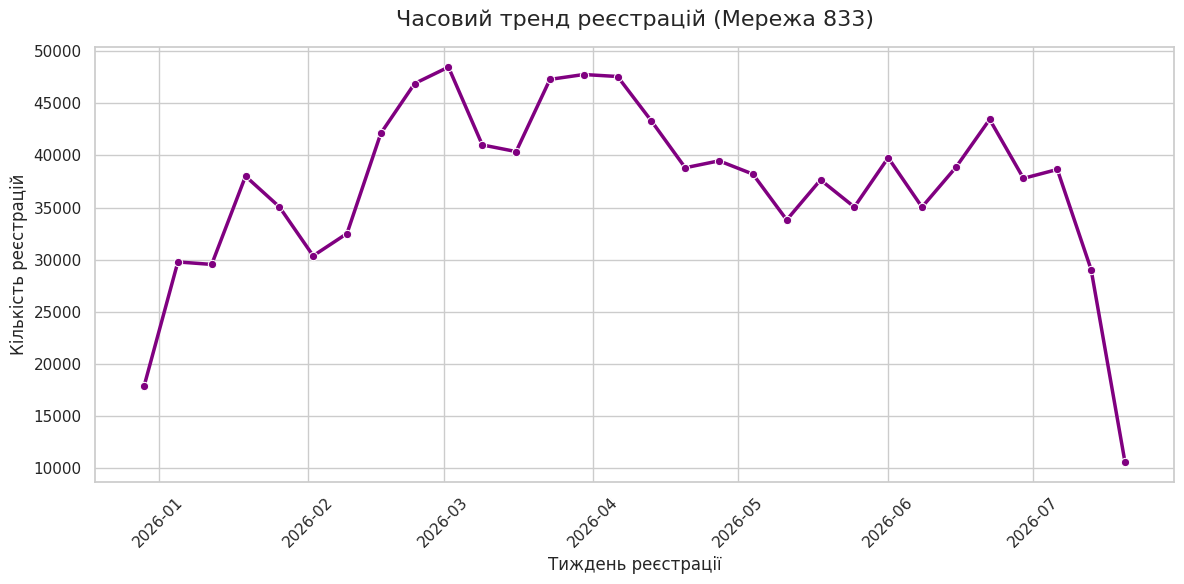

In [33]:
query_833_trend = """
    SELECT
        network,
        DATE_TRUNC('week', CAST(date_created AS TIMESTAMP)) AS reg_week,
        COUNT(*) AS weekly_regs
    FROM df_registrations
    WHERE network = '833'
    GROUP BY network, DATE_TRUNC('week', CAST(date_created AS TIMESTAMP))
    ORDER BY reg_week
"""

df_833_trend = duckdb.query(query_833_trend).df()

sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=df_833_trend,
    x='reg_week',
    y='weekly_regs',
    marker='o',
    linewidth=2.5,
    color='purple'
)

plt.title('Часовий тренд реєстрацій (Мережа 833)', fontsize=16, pad=15)
plt.xlabel('Тиждень реєстрації', fontsize=12)
plt.ylabel('Кількість реєстрацій', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

### тижневі реєстрації всіх мереж

303, 851 і 911 різко наростили трафік у березні - на початку квітня і так само різко скоротили його у квітні–травні, 303 до того ж майже не приводив користувачів з середини травня до середини червня. 413, 427 і 889 стартували з нуля в січні–лютому і росли поступово. Самі по собі різкі старти й паузи не означають фроду, але їх треба знати, щоб не прийняти зміну обсягу трафіку за зміну його якості.

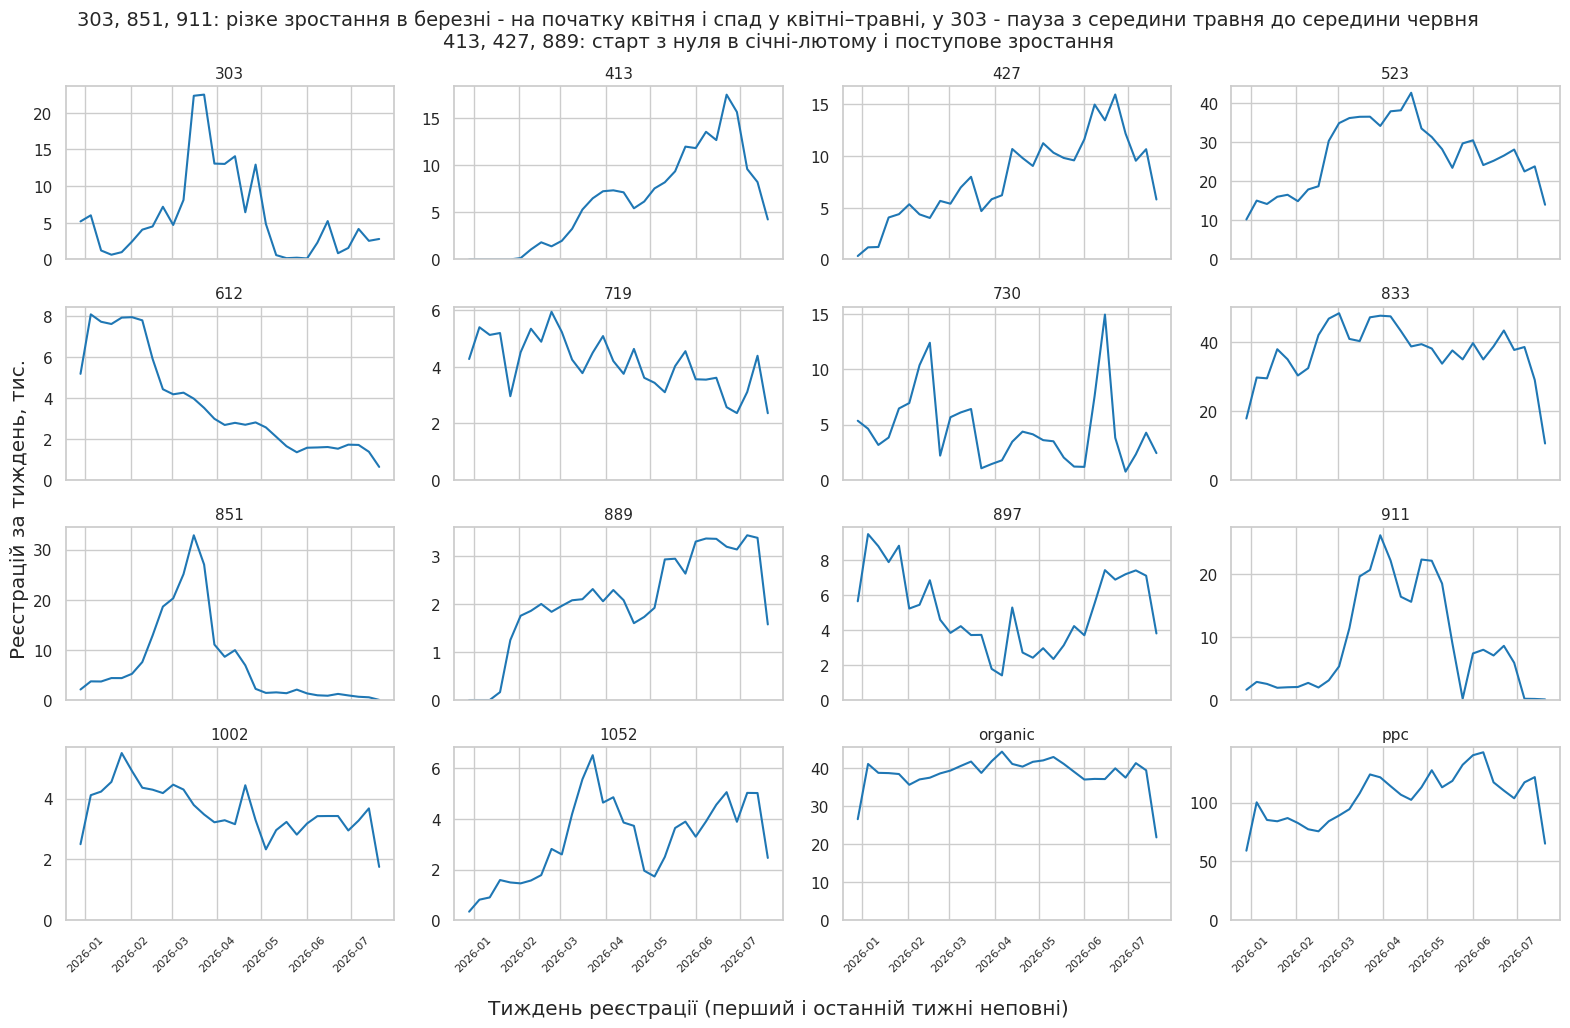

In [34]:
weekly = q("""
    SELECT network,
           DATE_TRUNC('week', date_created) AS week,
           COUNT(*) AS regs
    FROM df_registrations
    GROUP BY network, week
    ORDER BY network, week
""")

# Тиждень без реєстрацій у таблиці просто відсутній, і лінія перестрибнула б через паузу
# Тому розгортаємо в сітку «тиждень × мережа» і ставимо 0 там, де реєстрацій не було
grid = weekly.pivot(index='week', columns='network', values='regs').fillna(0)

nets = sorted(grid.columns, key=lambda n: (not str(n).isdigit(), int(n) if str(n).isdigit() else 0, str(n)))
ncols = 4
nrows = -(-len(nets) // ncols)   # ділення з округленням угору
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 2.6 * nrows), sharex=True)
for ax, n in zip(axes.flat, nets):
    ax.plot(grid.index, grid[n] / 1000, color='tab:blue')
    ax.set_title(n, fontsize=11)
    ax.set_ylim(bottom=0)
    ax.tick_params(axis='x', labelrotation=45, labelsize=8)
for ax in list(axes.flat)[len(nets):]:
    ax.set_visible(False)

title = "303, 851, 911: різке зростання в березні - на початку квітня і спад у квітні–травні, у 303 - пауза з середини травня до середини червня\n413, 427, 889: старт з нуля в січні-лютому і поступове зростання"
fig.suptitle(title, fontsize=14)
fig.supxlabel('Тиждень реєстрації (перший і останній тижні неповні)')
fig.supylabel('Реєстрацій за тиждень, тис.')
fig.tight_layout()
save(fig, '00_weekly_registrations')
plt.show()

## 2. Модель виплати і baseline: за що ми платимо кожному партнеру

### реєстрації з cost = NULL і конверсія в платника

In [35]:
query_users_cost = """
    SELECT
        network,

        SUM(CASE WHEN cost IS NULL THEN 1 ELSE 0 END) AS NULL_COUNT,
        ROUND(SUM(CASE WHEN cost IS NULL THEN 1 ELSE 0 END) * 100.0 / COUNT(*), 2) AS NULL_PCT,

        SUM(CASE WHEN cost IS NOT NULL THEN 1 ELSE 0 END) AS NOT_NULL_COUNT,
        ROUND(SUM(CASE WHEN cost IS NOT NULL THEN 1 ELSE 0 END) * 100.0 / COUNT(*), 2) AS NOT_NULL_PCT

    FROM df_registrations
    GROUP BY network
    ORDER BY NOT_NULL_COUNT DESC
"""

display(duckdb.query(query_users_cost).df())

,network,NULL_COUNT,NULL_PCT,NOT_NULL_COUNT,NOT_NULL_PCT
0,ppc,19376.0,0.62,3098532.0,99.38
1,833,732645.0,65.76,381557.0,34.24
2,523,500415.0,63.30,290134.0,36.70
3,427,52467.0,22.59,179784.0,77.41
4,413,41446.0,22.48,142948.0,77.52
5,303,54650.0,31.29,119987.0,68.71
6,730,38435.0,28.00,98817.0,72.00
7,897,56921.0,37.11,96445.0,62.89
8,719,46074.0,37.39,77158.0,62.61
9,851,166139.0,75.71,53312.0,24.29


In [36]:
query_833_countries = """
    SELECT
        country,
        COUNT(*) AS unpaid_registrations,
        ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) AS percentage_pct
    FROM df_registrations
    WHERE network = '833' AND cost IS NULL
    GROUP BY country
    ORDER BY unpaid_registrations DESC
    LIMIT 10
"""
display(duckdb.query(query_833_countries).df())

,country,unpaid_registrations,percentage_pct
0,US,515499,70.36
1,GB,86804,11.85
2,CA,69257,9.45
3,AU,36534,4.99
4,NZ,15629,2.13
5,IE,7945,1.08
6,BE,292,0.04
7,PR,119,0.02
8,MX,43,0.01
9,NL,40,0.01


In [37]:
query_523_countries = """
    SELECT
        country,
        COUNT(*) AS unpaid_registrations,
        ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) AS percentage_pct
    FROM df_registrations
    WHERE network = '523' AND cost IS NULL
    GROUP BY country
    ORDER BY unpaid_registrations DESC
    LIMIT 10
"""
display(duckdb.query(query_523_countries).df())

,country,unpaid_registrations,percentage_pct
0,US,195073,38.98
1,BR,167371,33.45
2,GB,29773,5.95
3,CA,15441,3.09
4,MX,12655,2.53
5,PT,9918,1.98
6,VN,7594,1.52
7,AU,5469,1.09
8,IT,5352,1.07
9,NL,5092,1.02


In [38]:
query_conversion = """
    SELECT
        r.network,
        COUNT(DISTINCT r.id_user) AS total_users,
        COUNT(DISTINCT CASE WHEN p.status = 'success' THEN r.id_user END) AS paying_users,
        ROUND(
            COUNT(DISTINCT CASE WHEN p.status = 'success' THEN r.id_user END) * 100.0 /
            COUNT(DISTINCT r.id_user)
        , 2) AS conversion_rate_pct
    FROM df_registrations r
    LEFT JOIN df_payments p ON r.id_user = p.id_user
    GROUP BY r.network
    HAVING total_users > 100
    ORDER BY conversion_rate_pct ASC
"""

df_query_conversion = duckdb.query(query_conversion).df()
display(df_query_conversion)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,network,total_users,paying_users,conversion_rate_pct
0,911,267478,965,0.36
1,851,219451,908,0.41
2,523,790549,5639,0.71
3,833,1114202,13031,1.17
4,303,174637,2214,1.27
5,889,62118,1399,2.25
6,organic,1156766,27589,2.39
7,ppc,3117908,81055,2.60
8,612,111675,3247,2.91
9,719,123232,4280,3.47


### модель виплати: CPA чи CPS

Дві незалежні ознаки: частка платників серед реєстрацій, за які ми заплатили, і середня виплата за оплачену реєстрацію. Після розмітки порівнюємо мережі всередині своєї групи, а гіпотези будуємо під те, на чому заробляє саме цей партнер.

In [39]:
payout = q("""
    WITH payers AS (
        SELECT DISTINCT id_user FROM df_payments WHERE status = 'success'
    ),
    users AS (
        SELECT r.network,
               r.cost,
               CASE WHEN p.id_user IS NOT NULL THEN 1 ELSE 0 END AS is_payer
        FROM df_registrations r
        LEFT JOIN payers p ON r.id_user = p.id_user
        WHERE r.traffic_type = 'cpa'
    )
    SELECT network,
           COUNT(*)                                                        AS users,
           ROUND(100.0 * COUNT(cost) / COUNT(*), 2)                        AS paid_share_pct,          -- payout rate: за яку частку реєстрацій ми заплатили
           ROUND(100.0 * AVG(is_payer), 2)                                 AS conversion_pct,
           ROUND(100.0 * AVG(is_payer) FILTER (WHERE cost IS NOT NULL), 2) AS payers_among_paid_pct,   -- частка платників серед тих, за кого заплатили
           ROUND(100.0 * AVG(is_payer) FILTER (WHERE cost IS NULL), 2)     AS payers_among_unpaid_pct,
           ROUND(AVG(cost), 2)                                             AS avg_cost_per_paid_user,  -- AVG пропускає NULL: середня виплата за оплачену реєстрацію
           ROUND(SUM(cost), 0)                                             AS spend
    FROM users
    GROUP BY network
    ORDER BY payers_among_paid_pct DESC, avg_cost_per_paid_user DESC
""")
display(payout)

,network,users,paid_share_pct,conversion_pct,payers_among_paid_pct,payers_among_unpaid_pct,avg_cost_per_paid_user,spend
0,889,62118,1.68,2.25,100.00,0.58,278.85,291124.0
1,612,111675,2.08,2.91,83.52,1.19,502.67,1168206.0
2,1002,108535,5.93,6.69,68.71,2.78,382.25,2461660.0
3,1052,95788,13.38,3.86,19.89,1.38,150.11,1924382.0
4,427,232251,77.41,4.92,5.97,1.30,18.48,3322418.0
5,413,184394,77.52,4.77,5.76,1.38,19.11,2731467.0
6,719,123232,62.61,3.47,4.94,1.02,19.14,1476975.0
7,730,137252,72.00,4.12,4.86,2.22,14.60,1442696.0
8,897,153366,62.89,3.63,4.42,2.30,13.05,1258427.0
9,303,174637,68.71,1.27,1.53,0.70,2.82,338473.0


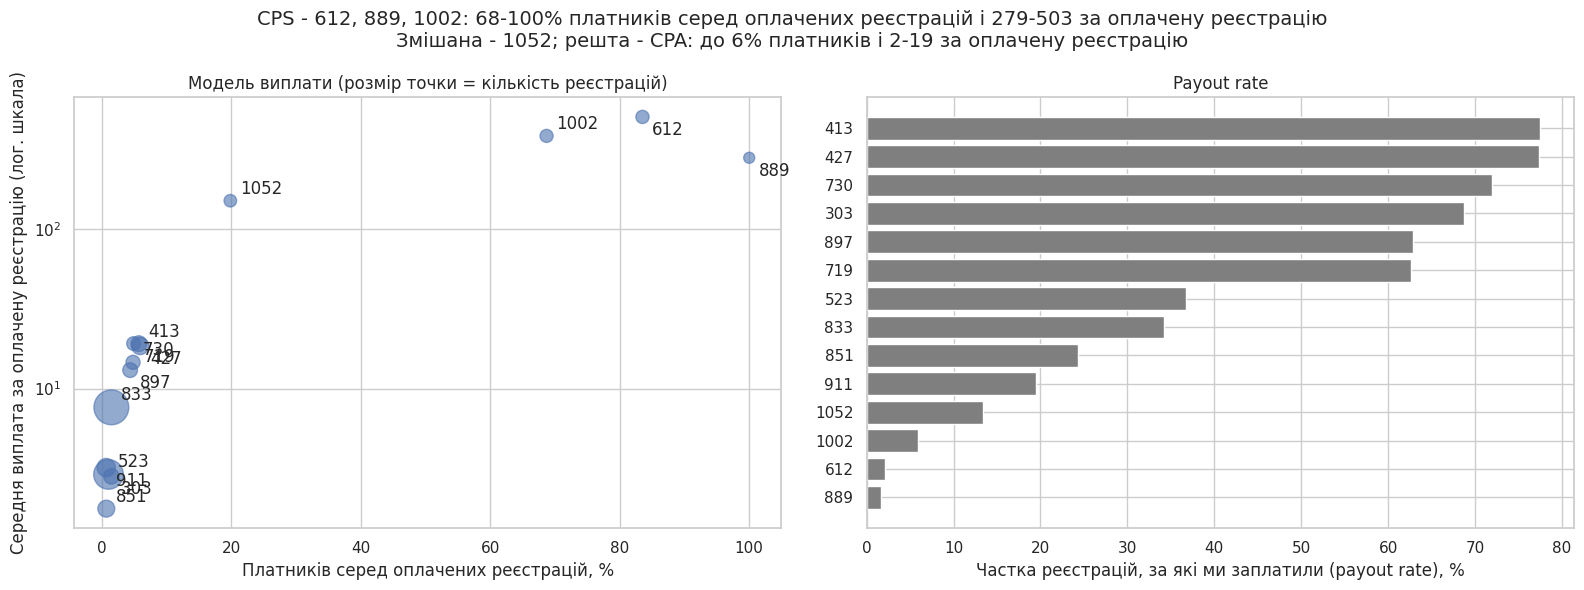

In [40]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

sizes = 30 + 600 * payout.users / payout.users.max()
ax1.scatter(payout.payers_among_paid_pct, payout.avg_cost_per_paid_user, s=sizes, alpha=0.6)
for k, (_, r) in enumerate(payout.sort_values('avg_cost_per_paid_user').iterrows()):
    ax1.annotate(r.network, (r.payers_among_paid_pct, r.avg_cost_per_paid_user),
                 xytext=(7, 5 if k % 2 == 0 else -13), textcoords='offset points')
ax1.set_yscale('log')
ax1.set_xlabel('Платників серед оплачених реєстрацій, %')
ax1.set_ylabel('Середня виплата за оплачену реєстрацію (лог. шкала)')
ax1.set_title('Модель виплати (розмір точки = кількість реєстрацій)')

p = payout.sort_values('paid_share_pct')
ax2.barh(p.network, p.paid_share_pct, color='tab:gray')
ax2.set_xlabel('Частка реєстрацій, за які ми заплатили (payout rate), %')
ax2.set_title('Payout rate')

title = "CPS - 612, 889, 1002: 68-100% платників серед оплачених реєстрацій і 279-503 за оплачену реєстрацію\nЗмішана - 1052; решта - CPA: до 6% платників і 2-19 за оплачену реєстрацію"
fig.suptitle(title, fontsize=14)
fig.tight_layout()
save(fig, '01_payout_model')
plt.show()

In [41]:
r = df_registrations[(df_registrations.network == '1052') & df_registrations.cost.notna()].copy()
r['is_payer'] = r.id_user.isin(df_payments.loc[df_payments.status == 'success', 'id_user'])
r.groupby('is_payer').cost.agg(['count', 'median', 'sum'])

,count,median,sum
is_payer,,,
False,10270,74.0,498501.74
True,2550,444.0,1425880.10


In [42]:
cps_networks = ['1002', '612', '889']
mixed_networks = ['1052']


def model_of(network):
    if network in ('ppc', 'organic'):
        return network
    if network in cps_networks:
        return 'CPS'
    if network in mixed_networks:
        return 'змішана'
    return 'CPA'


payout['model'] = payout.network.map(model_of)
display(payout[['network', 'model', 'paid_share_pct', 'payers_among_paid_pct', 'avg_cost_per_paid_user']])

,network,model,paid_share_pct,payers_among_paid_pct,avg_cost_per_paid_user
0,889,CPS,1.68,100.00,278.85
1,612,CPS,2.08,83.52,502.67
2,1002,CPS,5.93,68.71,382.25
3,1052,змішана,13.38,19.89,150.11
4,427,CPA,77.41,5.97,18.48
5,413,CPA,77.52,5.76,19.11
6,719,CPA,62.61,4.94,19.14
7,730,CPA,72.00,4.86,14.60
8,897,CPA,62.89,4.42,13.05
9,303,CPA,68.71,1.53,2.82


#### Висновок
CPS-мережі видно за двома незалежними ознаками: серед реєстрацій, за які ми платимо, 68-100% - платники, а виплата за оплачену реєстрацію - 279-503. Це 612, 889 і 1002, і далі вони порівнюються лише між собою. У CPA-мереж (303, 413, 427, 523, 719, 730, 833, 851, 897, 911) платників серед оплачених не більше 6%, а виплата - 2-19. 1052 - змішана модель: частину реєстрацій ми оплачуємо як CPA (медіана виплати 74), частину - як CPS (медіана 444 за платника). Тому висока конверсія 1002 (6,69%) - властивість CPS-моделі, а не ознака мотивованого трафіку.

#### Висновок: 833 - дві третини реєстрацій без виплати
- **Аномалія.** У найбільшого за реєстраціями партнера (1,11 млн, 14,3% бюджету CPA) за 65,8% реєстрацій виплати немає (cost = NULL).
- **Перевірка.** Для CPA-мереж це типово: у 523 без виплати 63,3% реєстрацій, у 851 і 911 - 76-81%. Сама мережа в нормі: chargeback у користувачах 1,84% - нижче PPC (2,49%), net ROAS 4,02 - близько до медіани партнерів (4,48), трафік рівний - 30-48 тис. реєстрацій на тиждень.
- **Висновок.** За реєстрації без виплати ми нічого не платимо, тож збитку від них немає. Найімовірніше, це умова контракту або не передані дані про виплату.
- **Рішення - норма.** Технічній команді - з'ясувати, чому для цих реєстрацій не записано cost.

## 3. Час від візиту на лендинг до реєстрації

### медіана, частка «≤5 с» і рівно 0 с

In [43]:
query_time_to_reg = """
    WITH time_diffs AS (
        SELECT
            network,
            DATE_DIFF('second', CAST(date_visit AS TIMESTAMP), CAST(date_created AS TIMESTAMP)) AS time_to_reg_sec
        FROM df_registrations
        WHERE date_visit IS NOT NULL AND date_created IS NOT NULL
    )
    SELECT
        network,
        COUNT(*) AS total_users,

        MEDIAN(time_to_reg_sec) AS median_time_sec,

        ROUND(SUM(CASE WHEN time_to_reg_sec <= 5 THEN 1 ELSE 0 END) * 100.0 / COUNT(*), 2) AS instant_reg_rate_pct,

        ROUND(SUM(CASE WHEN time_to_reg_sec = 3600 THEN 1 ELSE 0 END) * 100.0 / COUNT(*), 2) AS cron_3600s_rate_pct

    FROM time_diffs
    GROUP BY network
    HAVING total_users > 100 -- Відкидаємо статистичний шум
    ORDER BY instant_reg_rate_pct DESC, cron_3600s_rate_pct DESC
"""

df_time_to_reg = duckdb.query(query_time_to_reg).df()
display(df_time_to_reg)

,network,total_users,median_time_sec,instant_reg_rate_pct,cron_3600s_rate_pct
0,organic,1156766,46.0,8.53,0.0
1,612,111675,151.0,0.84,0.0
2,1002,108535,117.0,0.59,0.0
3,719,123232,164.0,0.52,0.0
4,ppc,3117908,236.0,0.44,0.0
5,851,219451,128.0,0.44,0.0
6,833,1114202,128.0,0.33,0.0
7,897,153366,245.0,0.32,0.0
8,889,62118,167.0,0.29,0.0
9,523,790549,112.0,0.28,0.0


In [44]:
query_artifact_check = """
    SELECT
        network,
        COUNT(*) AS total_users,
        SUM(CASE WHEN DATE_DIFF('second', CAST(date_visit AS TIMESTAMP), CAST(date_created AS TIMESTAMP)) = 0 THEN 1 ELSE 0 END) AS exact_match_count,
        ROUND(SUM(CASE WHEN DATE_DIFF('second', CAST(date_visit AS TIMESTAMP), CAST(date_created AS TIMESTAMP)) = 0 THEN 1 ELSE 0 END) * 100.0 / COUNT(*), 2) AS exact_match_pct
    FROM df_registrations
    WHERE date_visit IS NOT NULL AND date_created IS NOT NULL
    GROUP BY network
    ORDER BY exact_match_pct DESC
"""
display(duckdb.query(query_artifact_check).df())

,network,total_users,exact_match_count,exact_match_pct
0,organic,1156766,63046.0,5.45
1,612,111675,859.0,0.77
2,1002,108535,522.0,0.48
3,719,123232,546.0,0.44
4,ppc,3117908,11775.0,0.38
5,851,219451,803.0,0.37
6,889,62118,177.0,0.28
7,833,1114202,3142.0,0.28
8,897,153366,402.0,0.26
9,523,790549,1744.0,0.22


### форма розподілу проти медіани CPA-мереж

Еталон - інші CPA-мережі, не органіка. Дивимось на весь розподіл: вузький пік підмішаних реєстрацій не видно ні в медіані, ні в частці «≤5 с».

In [45]:
ttr = q("""
    WITH t AS (
        SELECT network,
               DATE_DIFF('second', date_visit, date_created) AS sec
        FROM df_registrations
        WHERE traffic_type = 'cpa'
    ),
    totals AS (
        SELECT network, COUNT(*) AS total FROM t GROUP BY network
    )
    SELECT t.network,
           CAST(FLOOR(t.sec / 5) * 5 AS INTEGER)       AS bin_sec,    -- кошики по 5 секунд
           COUNT(*)                                     AS users,
           100.0 * COUNT(*) / ANY_VALUE(totals.total)   AS share_pct   -- частка від усіх реєстрацій мережі
    FROM t
    JOIN totals ON t.network = totals.network
    WHERE t.sec >= 0 AND t.sec < 600
    GROUP BY t.network, bin_sec
""")

shares = ttr.pivot(index='bin_sec', columns='network', values='share_pct').fillna(0)
# Еталон для кожного кошика - медіана частки серед CPA-мереж
baseline = shares.median(axis=1)
excess = shares.sub(baseline, axis=0)   # на скільки п.п. мережа вища за еталон у кожному кошику

peak_bins = excess.idxmax()
peaks = pd.DataFrame({
    'peak_bin_sec': peak_bins,
    'share_in_peak_pct': [shares.at[b, n] for n, b in peak_bins.items()],
    'baseline_in_peak_pct': [baseline.at[b] for b in peak_bins],
    'excess_pp': excess.max(),
}).sort_values('excess_pp', ascending=False).round(2)
display(peaks)

,peak_bin_sec,share_in_peak_pct,baseline_in_peak_pct,excess_pp
network,,,,
523,25,3.98,0.02,3.95
1002,65,2.98,0.86,2.11
851,75,3.46,1.36,2.10
833,75,2.96,1.36,1.60
897,245,1.97,1.01,0.96
889,160,3.18,2.34,0.84
911,90,2.85,2.16,0.69
303,165,2.91,2.23,0.68
1052,55,1.03,0.45,0.58


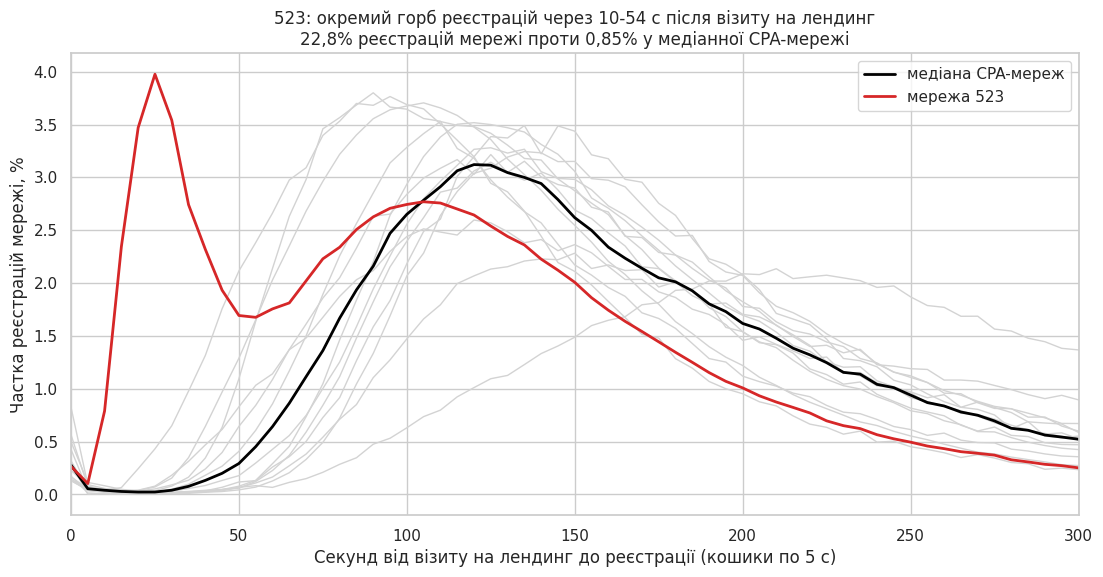

In [46]:
net_fast = peaks.index[0]   # мережа з найбільшим відхиленням від еталону

fig, ax = plt.subplots(figsize=(13, 6))
for n in shares.columns:
    ax.plot(shares.index, shares[n], color='lightgray', linewidth=1)
ax.plot(baseline.index, baseline, color='black', linewidth=2, label='медіана CPA-мереж')
ax.plot(shares.index, shares[net_fast], color='tab:red', linewidth=2, label=f'мережа {net_fast}')
ax.set_xlim(0, 300)
ax.set_xlabel('Секунд від візиту на лендинг до реєстрації (кошики по 5 с)')
ax.set_ylabel('Частка реєстрацій мережі, %')
title = "523: окремий горб реєстрацій через 10-54 с після візиту на лендинг\n22,8% реєстрацій мережі проти 0,85% у медіанної CPA-мережі"
ax.set_title(title)
ax.legend()
save(fig, '02_time_to_reg')
plt.show()

In [47]:
def segment_profile(network, segment_sql, label, compare_networks=()):
    """
    Порівнює сегмент мережі з рештою тієї ж мережі: той самий партнер і та сама угода, тому різниця - у самих користувачах
    """
    compare_list = ', '.join(f"'{n}'" for n in compare_networks) or 'NULL'
    sql = f"""
    WITH md AS (SELECT MAX(date_created) AS md FROM df_registrations),
    u AS (
        SELECT r.id_user, r.cost, r.date_created,
               CASE WHEN r.network = '{network}' AND ({segment_sql}) THEN '{network}: {label}'
                    WHEN r.network = '{network}' THEN '{network}: решта'
                    ELSE 'еталон' END AS segment,
               r.date_created <= (SELECT md FROM md) - INTERVAL 8 DAY AS is_mature -- D7 рахуємо лише для тих, у кого минуло 8 днів
        FROM df_registrations r
        WHERE r.network = '{network}' OR r.network IN ({compare_list})
    ),
    payers AS (SELECT DISTINCT id_user FROM df_payments WHERE status = 'success'),
    sessions AS (
        SELECT u.id_user,
               COUNT(*) AS sessions,
               MAX(CASE WHEN a.date_start BETWEEN u.date_created + INTERVAL 7 DAY
                                              AND u.date_created + INTERVAL 8 DAY THEN 1 ELSE 0 END) AS active_d7
        FROM u
        JOIN df_activity a ON a.id_user = u.id_user
        GROUP BY u.id_user
    )
    SELECT u.segment,
           COUNT(*)                                                                   AS users,
           ROUND(100.0 * COUNT(u.cost) / COUNT(*), 1)                                 AS paid_share_pct,
           ROUND(SUM(u.cost), 0)                                                      AS spend,
           ROUND(100.0 * COUNT(p.id_user) / COUNT(*), 2)                              AS payer_pct,
           ROUND(100.0 * AVG(COALESCE(s.active_d7, 0)) FILTER (WHERE u.is_mature), 2) AS d7_retention_pct,
           ROUND(AVG(COALESCE(s.sessions, 0)), 2)                                     AS avg_sessions,
           ROUND(100.0 * AVG(CASE WHEN s.id_user IS NULL THEN 1 ELSE 0 END), 1)       AS no_sessions_pct
    FROM u
    LEFT JOIN payers p   ON p.id_user = u.id_user
    LEFT JOIN sessions s ON s.id_user = u.id_user
    GROUP BY u.segment
    ORDER BY u.segment
    """
    out = q(sql)
    in_net = out.segment.str.startswith(f'{network}:')
    out['share_of_network_users_pct'] = (100 * out.users / out.users[in_net].sum()).where(in_net).round(1)
    out['share_of_network_spend_pct'] = (100 * out.spend / out.spend[in_net].sum()).where(in_net).round(1)
    return out

In [48]:
display(pd.DataFrame({'523': shares['523'], 'медіана CPA': baseline}).loc[0:100].round(2))

,523,медіана CPA
bin_sec,,
0,0.27,0.28
5,0.10,0.05
10,0.79,0.04
15,2.34,0.03
20,3.47,0.02
25,3.98,0.02
30,3.54,0.04
35,2.74,0.08
40,2.32,0.13


In [49]:
# Межі піку: суміжні кошики навколо піку, де частка мережі більш ніж удвічі вища за еталон
ratio = shares[net_fast] / baseline
lo = hi = int(peaks.at[net_fast, 'peak_bin_sec'])
while lo - 5 in ratio.index and ratio[lo - 5] > 2:
    lo -= 5
while hi + 5 in ratio.index and ratio[hi + 5] > 2:
    hi += 5
fast_from, fast_to = 10, 50 + 4

in_window = shares.loc[fast_from:fast_to].sum()   # частка реєстрацій кожної мережі в цьому вікні
print(f'Вікно {fast_from}–{fast_to} с: у мережі {net_fast} {in_window[net_fast]:.2f}% реєстрацій, '
      f'у медіанної CPA-мережі {in_window.median():.2f}%')

prof_fast = segment_profile(
    net_fast,
    f"DATE_DIFF('second', r.date_visit, r.date_created) BETWEEN {fast_from} AND {fast_to}",
    f'{fast_from}–{fast_to} с')
display(prof_fast)

Вікно 10–54 с: у мережі 523 22.81% реєстрацій, у медіанної CPA-мережі 0.85%


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,segment,users,paid_share_pct,spend,payer_pct,d7_retention_pct,avg_sessions,no_sessions_pct,share_of_network_users_pct,share_of_network_spend_pct
0,523: 10–54 с,180295,35.4,189804.0,0.35,0.87,1.37,54.7,22.8,22.6
1,523: решта,610254,37.1,650674.0,0.82,1.27,2.01,55.0,77.2,77.4


In [50]:
# Частка реєстрацій у вікні 10–54 с по всіх CPA-мережах - для порогу моніторингу 523
in_window.sort_values(ascending=False).round(2)

,0
network,
523,22.81
1002,7.59
833,3.57
1052,2.60
851,2.43
612,1.69
911,1.04
719,0.67
413,0.29


#### Висновок: 523 - клікери
- **Механізм.** 523 - CPA-мережа: ми платимо за реєстрацію. Частина реєстрацій проходить лендинг аномально швидко - за 10-54 с. Найімовірніше, це клікери: живі люди, яких спонукали зареєструватися. На ботів не схоже: 0,35% з них платять, а частка без жодної сесії така сама, як у решти мережі (54,7% проти 55,0%).
- **Доказ 1 - час реєстрації (графік 02).** У вікні 10-54 с - 22,8% реєстрацій 523 проти 0,85% у медіанної CPA-мережі (≈27×), вершина - 25 с (3,98% проти 0,02%). Найближча інша мережа - 1002 з 7,6%.
- **Доказ 2 - платежі.** Платників у сегменті 0,35% проти 0,82% у решти 523 - у 2,3 раза менше. У чистому трафіку швидкі реєстрації теж платять рідше, але лише в 1,5 раза (у PPC 1,76% проти 2,60%), тож розрив у 523 не пояснюється самою швидкістю реєстрації.
- **Масштаб.** 180 295 реєстрацій, 22,8% мережі. Ми заплатили за 35,4% з них - так само часто, як за решту мережі (37,1%): 189 804, або 22,6% витрат на 523.
- **Окупність.** Net ROAS 4,54 - на рівні медіани партнерів (4,48), по місяцях індекс тримається біля рівня партнерів (0,64-1,56, графік 07). Без витрат на сегмент net ROAS був би 5,87.
- **Рішення - переговори.** Фрод є, але мережа окупається. Вимога: не платити за реєстрації, швидші за 55 с (за період - 189 804), і прибрати джерело таких реєстрацій.
- **Моніторинг.** Щотижнева частка реєстрацій за 10-54 с, поріг - 10% (серед інших мереж максимум 7,6%).

In [51]:
# 1002 - друга мережа за часткою реєстрацій у вікні 10–54 с (7,6% при медіані CPA 0,85%).
# Порівнюємо цей сегмент з рештою 1002: чи платимо ми за ці реєстрації і чи стають вони платниками. Результат - у висновку 1002.
prof_fast_1002 = segment_profile(
    '1002',
    f"DATE_DIFF('second', r.date_visit, r.date_created) BETWEEN {fast_from} AND {fast_to}",
    f'{fast_from}–{fast_to} с')
display(prof_fast_1002)

,segment,users,paid_share_pct,spend,payer_pct,d7_retention_pct,avg_sessions,no_sessions_pct,share_of_network_users_pct,share_of_network_spend_pct
0,1002: 10–54 с,8240,6.0,65694.0,1.66,0.99,4.02,36.1,7.6,2.7
1,1002: решта,100295,5.9,2395967.0,7.10,4.71,14.86,36.0,92.4,97.3


In [52]:
# Контроль для 523 і 1002: чи швидкі реєстрації платять менше і в чистому трафіку. Еталон - PPC.
# Якщо в PPC швидкі платять майже як решта, то різниця в 523 і 1002 - ознака фроду, а не властивість швидких реєстрацій.
prof_fast_ppc = segment_profile(
    'ppc',
    "DATE_DIFF('second', r.date_visit, r.date_created) BETWEEN 10 AND 54",
    '10–54 с')
display(prof_fast_ppc)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,segment,users,paid_share_pct,spend,payer_pct,d7_retention_pct,avg_sessions,no_sessions_pct,share_of_network_users_pct,share_of_network_spend_pct
0,ppc: 10–54 с,15127,98.7,114516.0,1.76,3.87,8.05,38.0,0.5,0.5
1,ppc: решта,3102781,99.4,21396698.0,2.60,5.14,10.55,41.0,99.5,99.5


#### Висновок: контроль швидких реєстрацій на PPC
- **Навіщо:** перевірити, чи швидкі реєстрації платять менше і в чистому трафіку. Якщо так, частина розриву в 523 і 1002 - властивість самої швидкості, а не фрод.
- **PPC:** за 10-54 с реєструються лише 0,5% користувачів, і платять вони в 1,5 раза рідше за решту (1,76% проти 2,60%).
- **523:** розрив 2,3 раза (0,35% проти 0,82%) і окремий горб на 25 с - самою швидкістю це не пояснити, висновок про клікерів тримається.
- **1002:** розрив 4,3 раза (1,66% проти 7,10%), але окремого горба немає (вершина 65-69 с, надлишок 2,11 п.п. - як у 851), а платять швидкі 1002 так само, як швидкі в PPC (1,66% проти 1,76%). Доказ спірний, на сегмент іде 2,7% витрат на 1002 (65 694) - тому моніторинг, а не переговори.

## 4. Хто реєструється: метаюзери, пристрої, домени email

### метаюзери і пристрої


In [53]:
query_metauser = """
    SELECT
        network,
        id_metauser,
        COUNT(DISTINCT id_user) AS linked_accounts
    FROM df_registrations
    WHERE id_metauser IS NOT NULL
    GROUP BY network, id_metauser
    HAVING linked_accounts > 5 -- Відсікаємо нормальних юзерів (до 5 акаунтів на пристрій)
    ORDER BY linked_accounts DESC
    LIMIT 100
"""

df_meta_loop = duckdb.query(query_metauser).df()
display(df_meta_loop)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,network,id_metauser,linked_accounts
0,organic,310143367,4686
1,organic,271795623,2940
2,organic,1515218647,1629
3,organic,843314038,1618
4,organic,1145484741,1530
...,...,...,...
95,organic,1491126632,161
96,organic,1960792910,160
97,ppc,1584714252,159
98,organic,1980642206,159


In [54]:
query_metauser_sentinel = """
    SELECT
        id_metauser,
        COUNT(DISTINCT id_user) AS linked_users,
        COUNT(DISTINCT network) AS unique_networks,
        COUNT(DISTINCT device_OS) AS unique_os,
        COUNT(DISTINCT country) AS unique_countries
    FROM df_registrations
    WHERE id_metauser IS NOT NULL
    GROUP BY id_metauser
    HAVING COUNT(DISTINCT id_user) > 5
    ORDER BY linked_users DESC
    LIMIT 10
"""
display(duckdb.query(query_metauser_sentinel).df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,id_metauser,linked_users,unique_networks,unique_os,unique_countries
0,310143367,4704,4,3,1
1,271795623,3225,2,1,1
2,1515218647,1629,1,2,42
3,843314038,1618,1,3,13
4,1145484741,1530,1,1,1
5,298840506,1316,3,4,4
6,61382629,906,1,1,10
7,1250230901,756,3,2,1
8,121479450,704,1,2,7
9,608498860,651,3,1,1


In [55]:
query_meta_context = """
    WITH loops AS (
        SELECT id_metauser, country, COUNT(DISTINCT id_user) AS linked_accounts
        FROM df_registrations
        WHERE id_metauser IS NOT NULL
        GROUP BY id_metauser, country
    )
    SELECT
        country,
        COUNT(id_metauser) AS total_devices,
        AVG(linked_accounts) AS avg_accounts_per_device,
        MAX(linked_accounts) AS max_accounts_per_device,
        SUM(CASE WHEN linked_accounts > 5 THEN 1 ELSE 0 END) AS suspicious_devices
    FROM loops
    GROUP BY country
    ORDER BY suspicious_devices DESC
    LIMIT 10
"""
display(duckdb.query(query_meta_context).df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,country,total_devices,avg_accounts_per_device,max_accounts_per_device,suspicious_devices
0,US,2333445,1.313218,1530,26275.0
1,GB,364956,1.342765,3225,4596.0
2,CA,246441,1.388762,268,3977.0
3,BR,908453,1.182212,284,3260.0
4,AU,183066,1.370194,348,2744.0
5,NZ,48160,1.470785,296,987.0
6,MX,202669,1.147122,1311,684.0
7,CO,68633,1.252823,407,656.0
8,IN,77342,1.181376,633,532.0
9,ZA,121116,1.157378,153,505.0


In [56]:
query_devices = """
    SELECT
        device_OS,
        COUNT(*)
    FROM df_registrations
    GROUP BY device_OS
    ORDER BY COUNT(*) DESC
    LIMIT 100
"""

df_devices = duckdb.query(query_devices).df()
display(df_devices)

,device_os,count_star()
0,Android,5404392
1,iOS,2056284
2,Windows,431726
3,Mac,96341
4,unknown,60859


In [57]:
query_devices = """
    SELECT network,
        device_OS,
        COUNT(*)
    FROM df_registrations
    WHERE device_OS = 'unknown'
    GROUP BY network, device_OS
    ORDER BY COUNT(*) DESC
    LIMIT 100
"""

df_devices = duckdb.query(query_devices).df()
display(df_devices)

,network,device_os,count_star()
0,ppc,unknown,27399
1,organic,unknown,16906
2,833,unknown,2586
3,612,unknown,2547
4,719,unknown,2191
5,523,unknown,1452
6,1052,unknown,1423
7,851,unknown,1369
8,1002,unknown,1351
9,730,unknown,1018


In [58]:
query_devices_rate = """
    SELECT
        network,
        COUNT(*) AS total_users,
        SUM(CASE WHEN device_OS = 'unknown' THEN 1 ELSE 0 END) AS unknown_os_count,
        ROUND(SUM(CASE WHEN device_OS = 'unknown' THEN 1 ELSE 0 END) * 100.0 / COUNT(*), 2) AS unknown_os_rate_pct
    FROM df_registrations
    GROUP BY network
    HAVING total_users > 1000 -- відкидаємо мікро-мережі
    ORDER BY unknown_os_rate_pct DESC
    LIMIT 10
"""
display(duckdb.query(query_devices_rate).df())

,network,total_users,unknown_os_count,unknown_os_rate_pct
0,612,111675,2547.0,2.28
1,719,123232,2191.0,1.78
2,1052,95788,1423.0,1.49
3,organic,1156766,16906.0,1.46
4,1002,108535,1351.0,1.24
5,ppc,3117908,27399.0,0.88
6,730,137252,1018.0,0.74
7,889,62118,425.0,0.68
8,851,219451,1369.0,0.62
9,413,184394,534.0,0.29


### домени email: тимчасові пошти

Частка домену в мережі порівняно з PPC. Домен, якого в PPC майже немає, а в мережі він займає помітну частку, - кандидат у сервіс тимчасової пошти. Популярність звичайних поштовиків залежить від країни, тому відхилення gmail чи hotmail на кілька п.п. - ще не сигнал.

In [59]:
domains = q("""
    WITH d AS (
        SELECT network, traffic_type, LOWER(SPLIT_PART(email, '@', 2)) AS domain
        FROM df_registrations
        WHERE email IS NOT NULL
    ),
    by_network AS (
        SELECT network, domain,
               COUNT(*) AS users,
               100.0 * COUNT(*) / SUM(COUNT(*)) OVER (PARTITION BY network) AS share_pct
        FROM d
        WHERE traffic_type = 'cpa'
        GROUP BY network, domain
    ),
    ppc AS (
        SELECT domain, 100.0 * COUNT(*) / SUM(COUNT(*)) OVER () AS ppc_share_pct
        FROM d
        WHERE traffic_type = 'ppc'
        GROUP BY domain
    )
    SELECT b.network, b.domain, b.users,
           ROUND(b.share_pct, 2)                                    AS share_pct,
           ROUND(ppc.ppc_share_pct, 3)                              AS ppc_share_pct,
           ROUND(b.share_pct - COALESCE(ppc.ppc_share_pct, 0), 2)   AS excess_pp,     -- на скільки п.п. частка вища, ніж у PPC
           ROUND(b.share_pct / NULLIF(ppc.ppc_share_pct, 0), 1)     AS lift_vs_ppc    -- у скільки разів вища (NULL = домену в PPC немає)
    FROM by_network b
    LEFT JOIN ppc ON b.domain = ppc.domain
    WHERE b.share_pct >= 1
    ORDER BY excess_pp DESC, b.users DESC
""")
display(domains.head(15))

net_email = domains.network.iloc[0]
domain = domains.domain.iloc[0]
print(f'Далі дивимось на домен {domain} у мережі {net_email}')

,network,domain,users,share_pct,ppc_share_pct,excess_pp,lift_vs_ppc
0,911,tempmail.com,92072,34.42,0.000,34.42,1073254.7
1,897,yahoo.com,21980,14.33,5.080,9.25,2.8
2,427,yahoo.com,31028,13.36,5.080,8.28,2.6
3,413,yahoo.com,21279,11.54,5.080,6.46,2.3
4,1002,yahoo.com,11671,10.75,5.080,5.67,2.1
5,851,gmail.com,181312,82.62,77.249,5.37,1.1
6,833,icloud.com,70668,6.34,1.057,5.29,6.0
7,1052,yahoo.com,9739,10.17,5.080,5.09,2.0
8,523,gmail.com,643051,81.34,77.249,4.09,1.1
9,889,libero.it,2213,3.56,0.137,3.43,26.1


Далі дивимось на домен tempmail.com у мережі 911


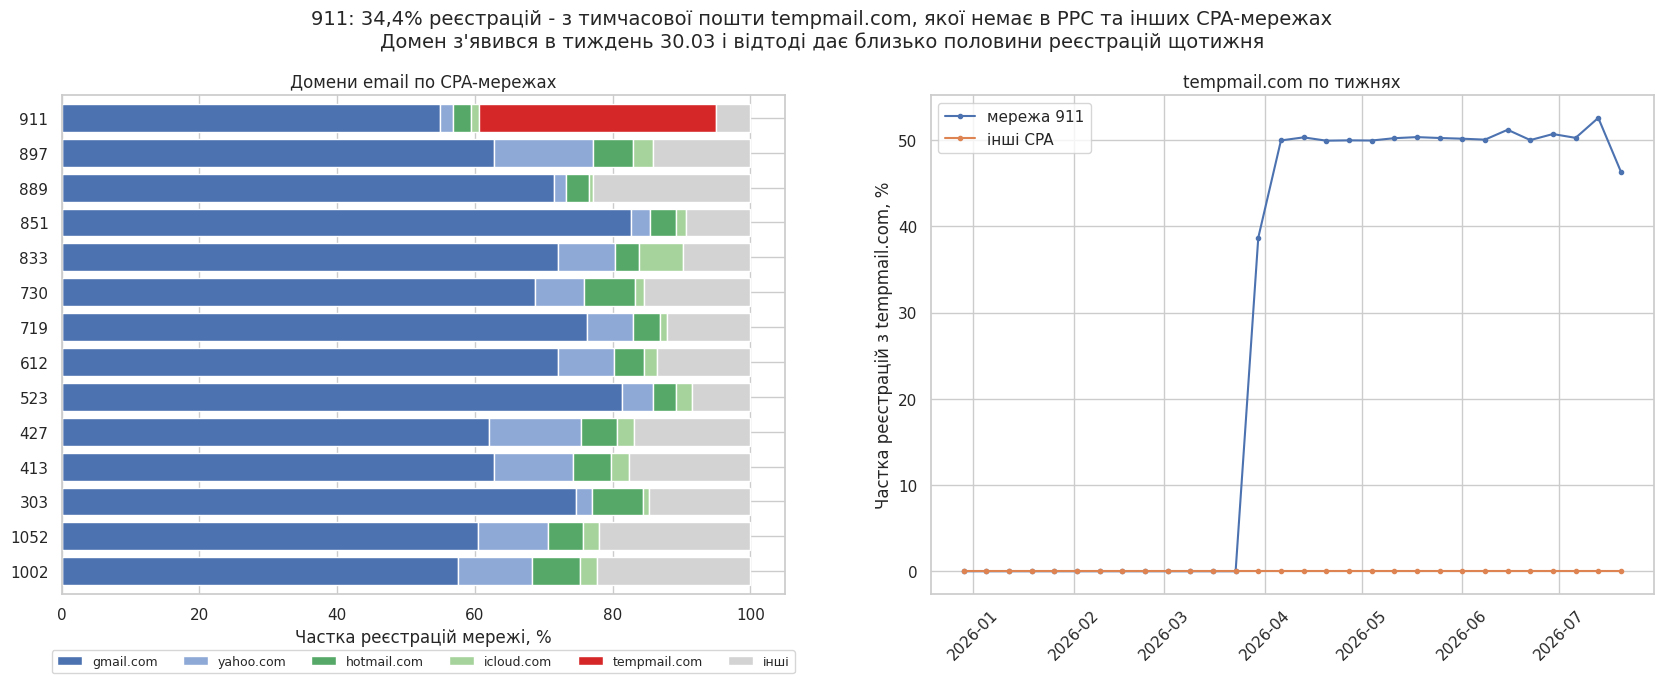

In [60]:
mix = q("""
    SELECT network, LOWER(SPLIT_PART(email, '@', 2)) AS domain, COUNT(*) AS users
    FROM df_registrations
    WHERE traffic_type = 'cpa' AND email IS NOT NULL
    GROUP BY network, domain
""")
top = mix.groupby('domain').users.sum().nlargest(4).index.tolist()
show = list(dict.fromkeys(top + [domain]))   # 4 найбільші домени + обраний, без повторів
mix['domain'] = mix.domain.where(mix.domain.isin(show), 'інші')
structure = mix.pivot_table(index='network', columns='domain', values='users', aggfunc='sum', fill_value=0)
structure = structure.div(structure.sum(axis=1), axis=0).mul(100)[show + ['інші']].sort_values(domain)

weekly_dom = q(f"""
    SELECT DATE_TRUNC('week', date_created) AS week,
           CASE WHEN network = '{net_email}' THEN 'мережа {net_email}' ELSE 'інші CPA' END AS grp,
           100.0 * AVG(CASE WHEN LOWER(SPLIT_PART(email, '@', 2)) = '{domain}' THEN 1 ELSE 0 END) AS share_pct
    FROM df_registrations
    WHERE traffic_type = 'cpa'
    GROUP BY week, grp
    ORDER BY week
""")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 7))
palette = ['#4c72b0', '#8fa9d6', '#55a868', '#a6d39c', '#c44e52', '#dd8452']
colors = {dom: ('tab:red' if dom == domain else 'lightgray' if dom == 'інші' else palette[k % len(palette)])
          for k, dom in enumerate(structure.columns)}   # обраний домен - червоним
structure.plot(kind='barh', stacked=True, ax=ax1, width=0.8, color=[colors[c] for c in structure.columns])
ax1.set_xlabel('Частка реєстрацій мережі, %')
ax1.set_ylabel('')
ax1.set_title('Домени email по CPA-мережах')
ax1.legend(loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=6, fontsize=9)
for grp, d in weekly_dom.groupby('grp'):
    ax2.plot(d.week, d.share_pct, marker='o', markersize=3, label=grp)
ax2.set_ylabel(f'Частка реєстрацій з {domain}, %')
ax2.set_title(f'{domain} по тижнях')
ax2.tick_params(axis='x', labelrotation=45)
ax2.legend()
title = "911: 34,4% реєстрацій - з тимчасової пошти tempmail.com, якої немає в PPC та інших CPA-мережах\nДомен з'явився в тиждень 30.03 і відтоді дає близько половини реєстрацій щотижня"
fig.suptitle(title, fontsize=14)
fig.tight_layout()
save(fig, '03_email_domains')
plt.show()

In [61]:
prof_email = segment_profile(net_email, f"LOWER(SPLIT_PART(r.email, '@', 2)) = '{domain}'", domain)
display(prof_email)

,segment,users,paid_share_pct,spend,payer_pct,d7_retention_pct,avg_sessions,no_sessions_pct,share_of_network_users_pct,share_of_network_spend_pct
0,911: tempmail.com,92072,18.1,22162.0,0.07,0.76,1.03,58.6,34.4,13.3
1,911: решта,175406,20.1,144543.0,0.51,0.60,1.11,69.3,65.6,86.7


#### Висновок: 911 - мотивований трафік з тимчасових пошт
- **Механізм.** 911 - CPA-мережа: ми платимо за реєстрацію. З кінця березня приблизно половина її реєстрацій іде з тимчасової пошти tempmail.com. Найімовірніше, це мотивований трафік: людей спонукають зареєструватися «на викид». Вони заходять у продукт не рідше за інших (D7 0,76% проти 0,60%; без жодної сесії 58,6% проти 69,3%), але майже не платять, тож це не боти.
- **Доказ 1 - домени email (графік 03).** tempmail.com - 92 072 реєстрації, 34,4% мережі. До тижня 30.03 цього домену не було, у тиждень 30.03 - 38,6%, далі близько 50% щотижня. У PPC та інших CPA-мережах його немає.
- **Доказ 2 - платежі.** Платників серед них 0,07% проти 0,51% у решти 911 - приблизно в 7 разів менше.
- **Масштаб.** За ці реєстрації ми заплатили 22 162 - 13,3% витрат на 911. Людей 34%, а грошей 13%, бо оплачена реєстрація з tempmail коштувала ≈1,33 проти ≈4,10 у решти мережі.
- **Окупність.** Загальний net ROAS 7,05 - найвищий серед партнерів, але його дають ранні когорти: індекс відносно всіх партнерів - 2,48 у лютому і 1,52 у березні, а з квітня - 0,78, 0,32, 1,19 і 0,27 (графік 07). З появою tempmail це збігається в часі, але сегмент - лише 13% витрат, тож одним ним падіння не пояснити: погіршилась і решта трафіку мережі (або в малій мережі когорти шумні).
- **Рішення - переговори з умовою.** Фрод є, загальна окупність добра, частка бюджету мала (0,8%). Вимога: не платити за реєстрації з тимчасових пошт (за період - 22 162). Якщо за 4 тижні частка не впаде - вимкнути: останні місяці і так гірші за партнерів.
- **Моніторинг.** Щотижнева частка реєстрацій з тимчасових доменів, поріг - 2% (в інших мережах - 0).

## 5. Chargeback

### chargeback у платежах за весь період

In [62]:
query_chargeback_rate = """
    SELECT
        network,
        COUNT(*) AS total_payments,
        ROUND(SUM(CASE WHEN chargeback_date IS NOT NULL THEN 1 ELSE 0 END) * 100.0 / SUM(CASE WHEN status='success' THEN 1 ELSE 0 END), 2) AS chargeback_rate
    FROM df_payments p
    LEFT JOIN df_registrations r ON p.id_user = r.id_user
    GROUP BY network
    ORDER BY chargeback_rate DESC
"""
display(duckdb.query(query_chargeback_rate).df())

,network,total_payments,chargeback_rate
0,612,11157,14.98
1,1052,51540,3.45
2,303,19377,0.59
3,911,9434,0.56
4,897,62490,0.47
5,833,119342,0.46
6,427,99648,0.46
7,730,49489,0.45
8,organic,441149,0.45
9,ppc,1173095,0.45


### chargeback у платежах, користувачах і грошах

Три різні питання: скільки платежів повернули, скільки людей це зробили, скільки грошей ми втратили. Кардинг видно в користувачах, один користувач з багатьма поверненнями роздуває відсоток у платежах і грошах, але не в користувачах.
Chargeback приходить із затримкою, тому рахуємо лише платежі, у яких уже минуло достатньо часу.

In [63]:
# Перевірки перед розрахунком: на яких статусах стоять chargeback і через скільки днів вони приходять
display(q("""
    SELECT status, COUNT(*) AS payments, COUNT(chargeback_date) AS with_chargeback
    FROM df_payments
    GROUP BY status
    ORDER BY status
"""))

lag = q("""
    SELECT DATE_DIFF('day', date_created, chargeback_date) AS days_to_cb
    FROM df_payments
    WHERE chargeback_date IS NOT NULL
""")
print(lag.days_to_cb.describe(percentiles=[.5, .9, .95, .99]).round(1).to_string())
for d in (30, 45, 60, 90):
    print(f'Частка chargeback, що прийшли протягом {d} днів: {(lag.days_to_cb <= d).mean():.1%}')

,status,payments,with_chargeback
0,fail,976473,0
1,success,1325218,7925


count    7925.0
mean       10.4
std        40.4
min      -161.0
50%        24.0
90%        50.0
95%        54.0
99%        58.0
max        60.0
Частка chargeback, що прийшли протягом 30 днів: 58.4%
Частка chargeback, що прийшли протягом 45 днів: 84.2%
Частка chargeback, що прийшли протягом 60 днів: 100.0%
Частка chargeback, що прийшли протягом 90 днів: 100.0%


In [64]:
neg = q("""
    SELECT r.network,
           COUNT(*)                                                   AS cb_payments,
           COUNT(*) FILTER (WHERE p.chargeback_date < p.date_created) AS cb_before_payment
    FROM df_payments p
    JOIN df_registrations r ON p.id_user = r.id_user
    WHERE p.chargeback_date IS NOT NULL
    GROUP BY r.network
""")
neg['share_pct'] = (100 * neg.cb_before_payment / neg.cb_payments).round(1)
display(neg.sort_values('cb_before_payment', ascending=False))
print(neg.cb_before_payment.sum(), 'з', neg.cb_payments.sum())

,network,cb_payments,cb_before_payment,share_pct
8,ppc,2882,959,33.3
4,1052,1134,500,44.1
10,organic,1164,391,33.6
1,612,1019,154,15.1
9,897,209,93,44.5
3,427,320,70,21.9
13,833,289,60,20.8
12,1002,224,59,26.3
5,730,143,39,27.3
11,413,207,37,17.9


2434 з 7925


#### Chargeback, датовані раніше за платіж
Таких 2 434 з 7 925 (30,7%), і вони є в усьому трафіку: PPC - 33,3%, органіка - 33,6%, 612 - 15,1%, 1052 - 44,1%. Це артефакт даних, а не ознака фроду, і порівняння мереж він не зсуває, тому в розрахунках такі chargeback лишаємо. З медіани днів до chargeback їх виключено.

In [65]:
CB_WINDOW_DAYS = 60

cb = q(f"""
    WITH cutoff AS (
        SELECT MAX(date_created) - INTERVAL {CB_WINDOW_DAYS} DAY AS d FROM df_payments
    ),
    p AS (   -- успішні платежі, по яких chargeback уже встиг би прийти
        SELECT r.network, p.id_user, p.amount, p.date_created, p.chargeback_date
        FROM df_payments p
        JOIN df_registrations r ON p.id_user = r.id_user
        WHERE p.status = 'success'
          AND p.date_created <= (SELECT d FROM cutoff)
    ),
    by_user AS (
        SELECT network, id_user,
               COUNT(*)                                                             AS payments,
               COUNT(chargeback_date)                                               AS cb_payments,
               SUM(amount)                                                          AS revenue,
               COALESCE(SUM(amount) FILTER (WHERE chargeback_date IS NOT NULL), 0)  AS cb_amount
        FROM p
        GROUP BY network, id_user
    ),
    agg AS (
        SELECT network,
               SUM(payments)                                                        AS payments,
               ROUND(100.0 * SUM(cb_payments) / SUM(payments), 2)                   AS cb_rate_payments_pct,
               COUNT(*)                                                             AS payers,
               COUNT(*) FILTER (WHERE cb_payments > 0)                              AS cb_users,
               ROUND(100.0 * COUNT(*) FILTER (WHERE cb_payments > 0) / COUNT(*), 2) AS cb_rate_users_pct,
               ROUND(100.0 * SUM(cb_amount) / SUM(revenue), 2)                      AS cb_rate_money_pct,
               ROUND(100.0 * MAX(cb_amount) / NULLIF(SUM(cb_amount), 0), 1)         AS top_user_share_of_cb_money_pct
        FROM by_user
        GROUP BY network
    ),
    lag AS (
        SELECT network, MEDIAN(DATE_DIFF('day', date_created, chargeback_date)) AS median_days_to_cb
        FROM p
        WHERE chargeback_date >= date_created   -- без chargeback, датованих раніше за платіж
        GROUP BY network
    ),
    spend AS (   -- скільки ми заплатили партнеру всього і за користувачів, які потім зробили chargeback
        SELECT network,
               SUM(cost)                                                                        AS spend,
               SUM(cost) FILTER (WHERE id_user IN (SELECT id_user FROM p WHERE chargeback_date IS NOT NULL)) AS spend_on_cb_users
        FROM df_registrations
        GROUP BY network
    )
    SELECT agg.*,
           lag.median_days_to_cb,
           ROUND(spend.spend_on_cb_users, 0)                                AS spend_on_cb_users,
           ROUND(100.0 * spend.spend_on_cb_users / NULLIF(spend.spend, 0), 1) AS spend_on_cb_users_pct
    FROM agg
    LEFT JOIN lag   ON agg.network = lag.network
    LEFT JOIN spend ON agg.network = spend.network
    ORDER BY cb_rate_users_pct DESC
""")
cb.insert(1, 'model', cb.network.map(model_of))
display(cb)

,network,model,payments,cb_rate_payments_pct,payers,cb_users,cb_rate_users_pct,cb_rate_money_pct,top_user_share_of_cb_money_pct,median_days_to_cb,spend_on_cb_users,spend_on_cb_users_pct
0,612,CPS,5260.0,14.73,2774,565,20.37,12.07,11.9,40.0,176258.0,15.1
1,organic,organic,148760.0,0.46,19519,579,2.97,0.46,3.0,33.0,NaN,NaN
2,897,CPA,25611.0,0.44,3450,94,2.72,0.44,9.4,35.5,865.0,0.1
3,ppc,ppc,376598.0,0.45,55365,1380,2.49,0.41,2.3,34.0,16471.0,0.1
4,1002,CPS,30557.0,0.47,5011,119,2.37,0.37,10.4,36.0,40862.0,1.7
5,719,CPA,18889.0,0.40,2884,68,2.36,0.28,8.0,34.0,4197.0,0.3
6,1052,змішана,16413.0,5.40,2092,49,2.34,21.24,98.0,23.0,14711.0,0.8
7,427,CPA,32736.0,0.45,6193,127,2.05,0.47,8.6,35.0,3517.0,0.1
8,730,CPA,25279.0,0.44,4714,95,2.02,0.39,11.4,38.0,1454.0,0.1
9,303,CPA,7224.0,0.60,1865,36,1.93,0.46,22.9,35.0,106.0,0.0


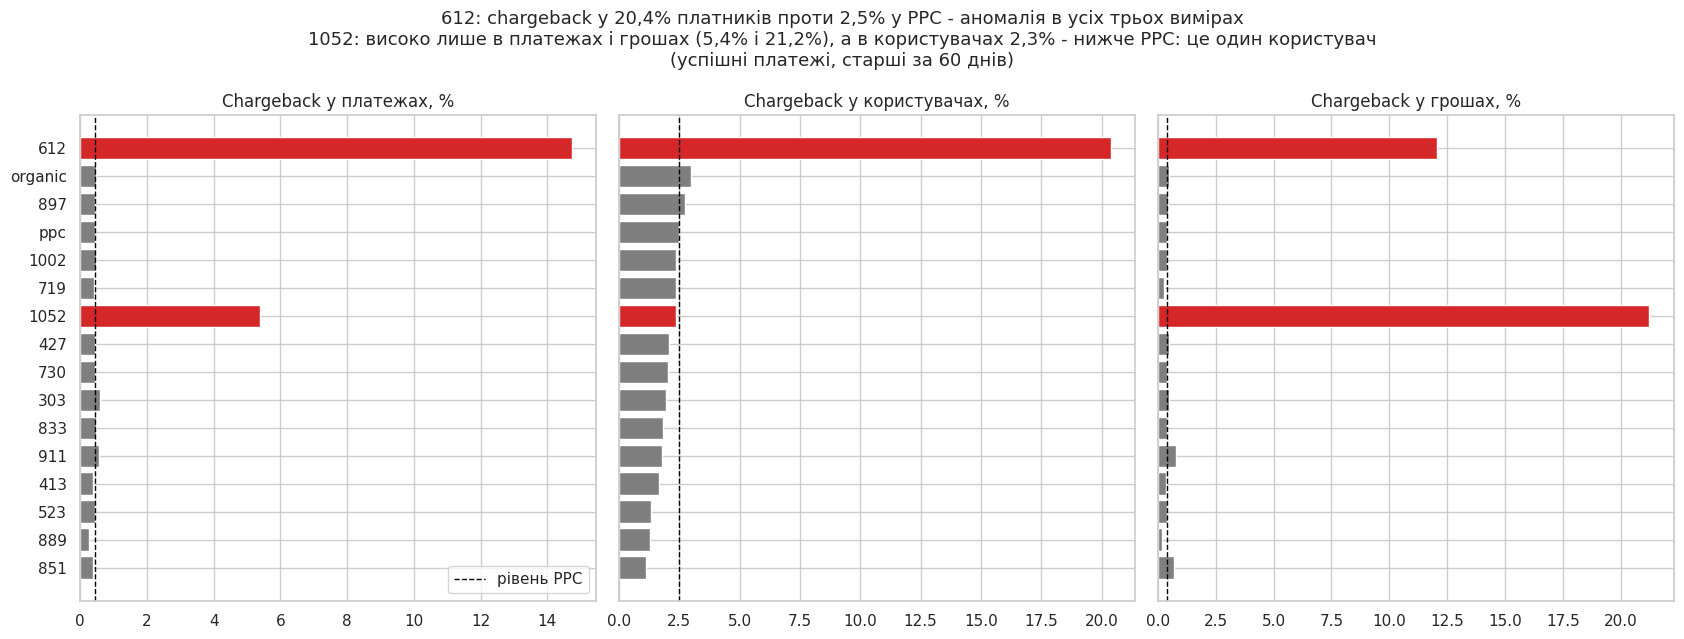

In [66]:
cols = ['cb_rate_payments_pct', 'cb_rate_users_pct', 'cb_rate_money_pct']
ppc_level = cb.set_index('network').loc['ppc', cols]
# Виділяємо партнерські мережі, де відсоток у платежах або в користувачах утричі вищий за PPC
above = (cb.cb_rate_payments_pct > 3 * ppc_level.cb_rate_payments_pct) | (cb.cb_rate_users_pct > 3 * ppc_level.cb_rate_users_pct)
highlight = cb.loc[above & ~cb.network.isin(['ppc', 'organic']), 'network'].tolist()

d = cb.set_index('network').sort_values('cb_rate_users_pct')
fig, axes = plt.subplots(1, 3, figsize=(17, 6.5), sharey=True)
for ax, col, name in zip(axes, cols, ['у платежах', 'у користувачах', 'у грошах']):
    colors = ['tab:red' if n in highlight else 'tab:gray' for n in d.index]
    ax.barh(d.index, d[col], color=colors)
    ax.axvline(ppc_level[col], color='black', linestyle='--', linewidth=1, label='рівень PPC')
    ax.set_title(f'Chargeback {name}, %')
axes[0].legend()
title = "612: chargeback у 20,4% платників проти 2,5% у PPC - аномалія в усіх трьох вимірах\n1052: високо лише в платежах і грошах (5,4% і 21,2%), а в користувачах 2,3% - нижче PPC: це один користувач"
fig.suptitle(f'{title}\n(успішні платежі, старші за {CB_WINDOW_DAYS} днів)', fontsize=13)
fig.tight_layout()
save(fig, '04_chargeback')
plt.show()

In [67]:
net_cb = '1052'

if net_cb == '...':
    print('...')
else:
    top_cb = q(f"""
        SELECT p.id_user,
               COUNT(*)                                                    AS success_payments,
               SUM(p.amount)                                               AS revenue,
               COUNT(p.chargeback_date)                                    AS cb_payments,
               SUM(p.amount) FILTER (WHERE p.chargeback_date IS NOT NULL)  AS cb_amount
        FROM df_payments p
        JOIN df_registrations r ON p.id_user = r.id_user
        WHERE r.network = '{net_cb}' AND p.status = 'success'
        GROUP BY p.id_user
        HAVING COUNT(p.chargeback_date) > 0
        ORDER BY cb_amount DESC
    """)
    top_cb['share_of_network_cb_money_pct'] = (100 * top_cb.cb_amount / top_cb.cb_amount.sum()).round(1)
    display(top_cb.head(15))

,id_user,success_payments,revenue,cb_payments,cb_amount,share_of_network_cb_money_pct
0,153952457,1005,1461600.0,1005,1461600.0,97.1
1,146587450,253,166695.0,4,4400.0,0.3
2,158529105,879,451765.0,6,2165.0,0.1
3,152321556,401,133015.0,1,2000.0,0.1
4,149732789,182,241365.0,1,2000.0,0.1
5,177505239,49,53295.0,1,2000.0,0.1
6,169290289,45,39850.0,1,2000.0,0.1
7,170338764,83,142750.0,1,2000.0,0.1
8,156927599,63,113290.0,1,2000.0,0.1
9,148029529,126,86240.0,2,1600.0,0.1


In [68]:
# Перевірка без топ-користувача: chargeback у грошах 1052 на тих самих платежах, що й у таблиці cb (старших за 60 днів).
# Користувача прибираємо і з повернень (чисельник), і з платежів (знаменник).
q(f"""
    SELECT ROUND(100.0 * SUM(p.amount) FILTER (WHERE p.chargeback_date IS NOT NULL) / SUM(p.amount), 2) AS cb_rate_money_pct
    FROM df_payments p
    JOIN df_registrations r ON p.id_user = r.id_user
    WHERE r.network = '{net_cb}' AND p.status = 'success'
      AND p.date_created <= (SELECT MAX(date_created) - INTERVAL {CB_WINDOW_DAYS} DAY FROM df_payments)
      AND p.id_user <> (SELECT id_user FROM top_cb ORDER BY cb_amount DESC LIMIT 1)
""")

,cb_rate_money_pct
0,0.52


#### Висновок: 612 - кардинг
- **Механізм.** 612 - CPS-мережа: ми платимо ~503 за кожного платника. Кардинг: «платник» розраховується чужою карткою, партнер отримує виплату, а згодом банк повертає гроші власнику картки (chargeback). Ми втрачаємо і виплату партнеру, і дохід.
- **Доказ 1 - chargeback (графік 04).** Chargeback зробили 20,4% платників (565 з 2 774) проти 2,5% у PPC - у 8 разів більше - і 1,3-2,4% в інших CPS-мережах (889, 1002).
- **Доказ 2 - окупність.** Gross ROAS 0,94 - єдина мережа, яка не окупається ще до вирахування chargeback; по місяцях окупність у 2,4–14 разів нижча за партнерів (індекс 0,07–0,42, графік 07).
- **Додаткове спостереження.** 632 користувачі отримали кредити, маючи лише невдалу оплату, в інших мережах такого немає. Механізм не встановлено.
- **Масштаб.** За користувачів, які потім зробили chargeback, ми заплатили 176 258 - 15,1% витрат на 612; chargeback забрав 104 500 доходу.
- **Окупність.** Net ROAS 0,85 - єдиний нижче 1, мережа займає 5,7% бюджету CPA, дохід після chargeback на 178 621 менший за витрати. Навіть без витрат на користувачів з chargeback net ROAS - лише 1,00.
- **Рішення - вимкнути.** Фрод і погана окупність. Вимагати повернення 176 258 за користувачів з chargeback.
- **Моніторинг.** Частка платників з chargeback (на платежах, старших за 60 днів), поріг - 4% (максимум серед «здорових» мереж - 2,97% в органіці).

#### Висновок: 1052 - не фрод мережі, а один користувач
- **Що бачимо.** Chargeback у платежах 5,40% і в грошах 21,24% (у PPC 0,45% і 0,41%), але в користувачах 2,34% - нижче PPC (2,49%). Так виглядає концентрація, а не масовий фрод.
- **Пояснення.** Один користувач зробив 1 005 успішних платежів на 1 461 600 і всі повернув через chargeback. На нього припадає 97% грошей chargeback мережі, на наступного - 0,3%.
- **Перевірка без нього.** Якщо прибрати і його повернення, і його платежі, chargeback у грошах ≈0,5% - як у решти мереж без кардингу (0,2-0,8%) і близько до PPC (0,41%).
- **Окупність.** Gross ROAS 5,39, net - 4,61: найбільший розрив серед мереж (0,78), бо з 1,51 млн повернутих грошей 1,46 млн - цей користувач. Мережа займає 9,4% бюджету CPA.
- **Рішення - моніторинг.** Партнер не постачає фрод систематично, тож вимикати його чи вимагати чогось немає підстав. Окремо, на рівні антифроду користувачів: заблокувати цього користувача і обмежити кількість платежів на одного користувача.
- **Моніторинг.** Chargeback у грошах і в користувачах разом. Сигнал - у грошах утричі вище за PPC (понад 1,2%), а в користувачах не вище PPC (до 2,5%): тоді перевіряємо топ-користувачів.

## 6. Гео і відмови в оплаті

### країни і години реєстрації

In [69]:
query_country = """
    SELECT
        country,
        COUNT(*)
    FROM df_registrations
    GROUP BY country
    ORDER BY COUNT(*) DESC
    LIMIT 10
"""

df_country = duckdb.query(query_country).df()
display(df_country)

,country,count_star()
0,US,3071694
1,BR,1074016
2,GB,492582
3,CA,342945
4,AU,251059
5,MX,232800
6,ZA,140249
7,KE,134756
8,FR,134104
9,IT,123423


In [70]:
query_hourly_spikes = """
    WITH hourly_stats AS (
        SELECT
            network,
            country,
            EXTRACT(HOUR FROM CAST(date_created AS TIMESTAMP)) AS reg_hour_utc,
            COUNT(id_user) AS hourly_regs
        FROM df_registrations
        WHERE date_created IS NOT NULL AND country IS NOT NULL
        GROUP BY network, country, EXTRACT(HOUR FROM CAST(date_created AS TIMESTAMP))
    ),
    traffic_shares AS (
        SELECT
            network,
            country,
            reg_hour_utc,
            hourly_regs,
            -- Рахуємо загальну кількість для цієї мережі і країни
            SUM(hourly_regs) OVER(PARTITION BY network, country) AS total_regs,
            -- Рахуємо відсоток трафіку, який припав саме на цю годину
            ROUND(hourly_regs * 100.0 / SUM(hourly_regs) OVER(PARTITION BY network, country), 2) AS traffic_share_pct
        FROM hourly_stats
    )
    SELECT *
    FROM traffic_shares
    WHERE total_regs > 500 -- Відкидаємо мікро-сегменти, де 5 випадкових реєстрацій дадуть "аномальні" 100%
    ORDER BY traffic_share_pct DESC
"""

df_hourly = duckdb.query(query_hourly_spikes).df()
display(df_hourly)

,network,country,reg_hour_utc,hourly_regs,total_regs,traffic_share_pct
0,851,SA,13,154,867.0,17.76
1,851,SA,12,130,867.0,14.99
2,organic,CN,3,2129,14827.0,14.36
3,organic,UA,13,256,1828.0,14.00
4,851,LV,6,71,528.0,13.45
...,...,...,...,...,...,...
12163,897,GR,1,1,514.0,0.19
12164,851,LV,1,1,528.0,0.19
12165,organic,CN,19,20,14827.0,0.13
12166,organic,CN,20,18,14827.0,0.12


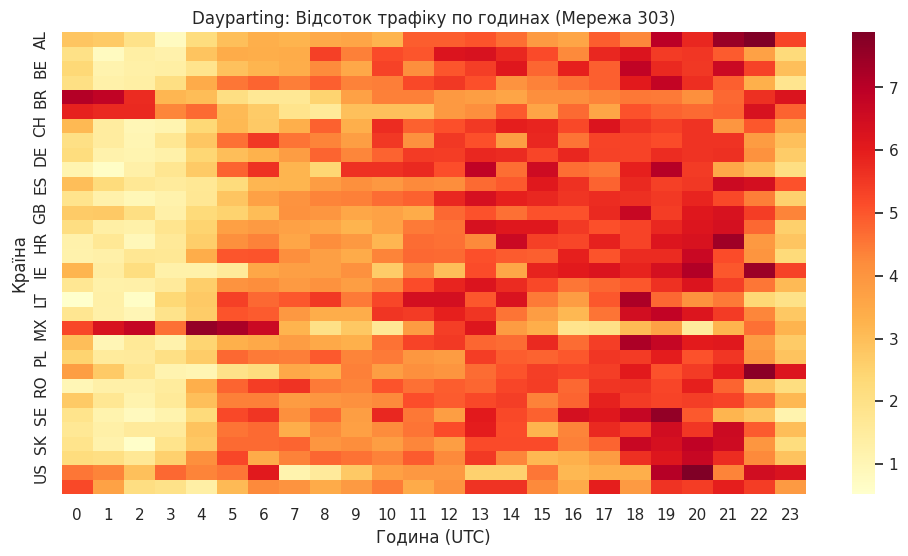

In [71]:
import seaborn as sns
import matplotlib.pyplot as plt

df_plot = df_hourly[df_hourly['network'] == '303']

pivot_table = df_plot.pivot(index='country', columns='reg_hour_utc', values='traffic_share_pct').fillna(0)

plt.figure(figsize=(12, 6))
sns.heatmap(pivot_table, cmap="YlOrRd", annot=False)
plt.title("Dayparting: Відсоток трафіку по годинах (Мережа 303)")
plt.xlabel("Година (UTC)")
plt.ylabel("Країна")
plt.show()

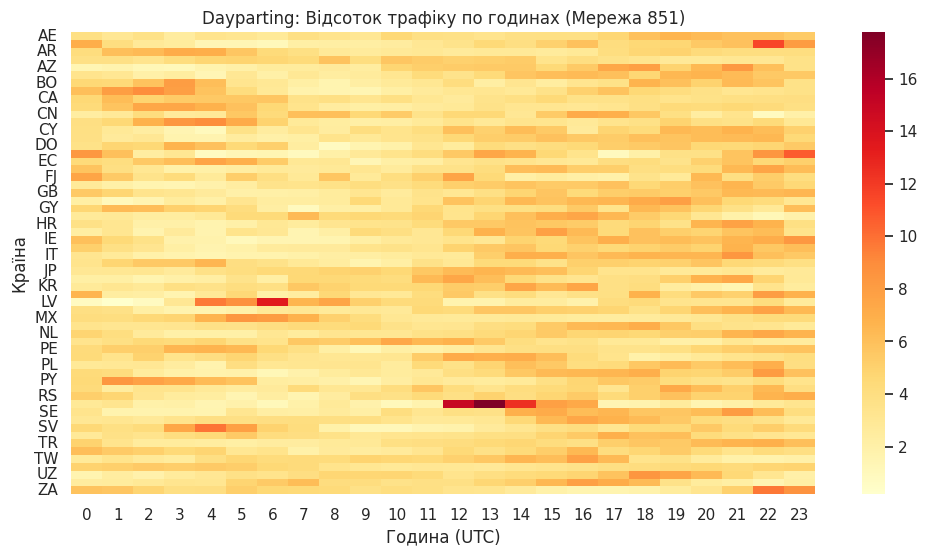

In [72]:
import seaborn as sns
import matplotlib.pyplot as plt

df_plot = df_hourly[df_hourly['network'] == '851']

pivot_table = df_plot.pivot(index='country', columns='reg_hour_utc', values='traffic_share_pct').fillna(0)

plt.figure(figsize=(12, 6))
sns.heatmap(pivot_table, cmap="YlOrRd", annot=False)
plt.title("Dayparting: Відсоток трафіку по годинах (Мережа 851)")
plt.xlabel("Година (UTC)")
plt.ylabel("Країна")
plt.show()

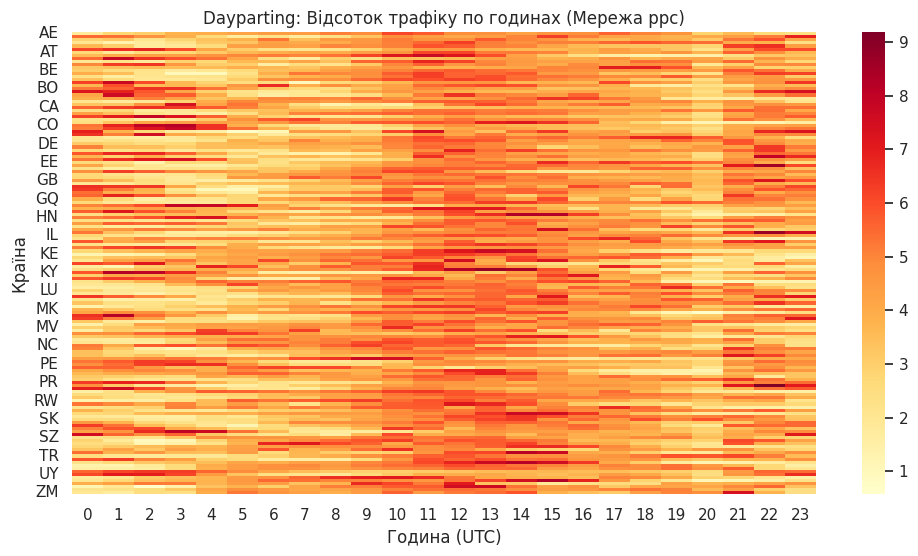

In [73]:
import seaborn as sns
import matplotlib.pyplot as plt

df_plot = df_hourly[df_hourly['network'] == 'ppc']

pivot_table = df_plot.pivot(index='country', columns='reg_hour_utc', values='traffic_share_pct').fillna(0)

plt.figure(figsize=(12, 6))
sns.heatmap(pivot_table, cmap="YlOrRd", annot=False)
plt.title("Dayparting: Відсоток трафіку по годинах (Мережа ppc)")
plt.xlabel("Година (UTC)")
plt.ylabel("Країна")
plt.show()

### розбіжність країни реєстрації і країни картки
Перше порівняння дає 98,7-100% розбіжності в усіх мережах: країна реєстрації записана в ISO2 (TR), а країна платежу - в ISO3 (TUR). Ручний мапінг 15 країн з SUBSTRING для решти знижує її до 24,5% у 303, 15,5% у 851 і 9,0% у PPC (на спробах оплати), але й ці числа завищені: правило «перші дві літери ISO3 = ISO2» хибне для 93 з 250 країн (TUR -> TU, SVN -> SV), а частина країн платежу записана в ISO2. Точний розрахунок - у наступному блоці: повний довідник, рахунок на платниках і очікуваний рівень за складом країн (303 - 9,2% при очікуваних 11,6%, PPC - 5,5%, графік 05).


In [74]:
query_geo_mismatch = """
    SELECT
        r.network,
        --кількість спроб платежів у цій мережі
        COUNT(p.id_user) AS total_payment_attempts,

        --кількість платежів із розбіжністю в країнах
        SUM(CASE WHEN r.country != p.country_payment THEN 1 ELSE 0 END) AS mismatch_count,
        -- Mismatch Rate
        ROUND(
            SUM(CASE WHEN r.country != p.country_payment THEN 1 ELSE 0 END) * 100.0 /
            COUNT(p.id_user)
        , 2) AS mismatch_rate_pct
    FROM df_registrations r
    JOIN df_payments p ON r.id_user = p.id_user
    WHERE r.country IS NOT NULL AND p.country_payment IS NOT NULL
    GROUP BY r.network
    HAVING total_payment_attempts > 50
    ORDER BY mismatch_rate_pct DESC
"""

df_geo_mismatch = duckdb.query(query_geo_mismatch).df()
display(df_geo_mismatch)

,network,total_payment_attempts,mismatch_count,mismatch_rate_pct
0,719,53665,53665.0,100.00
1,523,40500,40500.0,100.00
2,1052,51287,51287.0,100.00
3,889,14822,14822.0,100.00
4,833,118494,118490.0,100.00
5,851,9748,9748.0,100.00
6,413,70349,70349.0,100.00
7,organic,424511,424445.0,99.98
8,ppc,1089350,1089139.0,99.98
9,1002,66647,66627.0,99.97


In [75]:
query_debug_geo = """
    SELECT
        r.country AS reg_country,
        p.country_payment AS pay_country,
        COUNT(*) AS amount_of_cases
    FROM df_registrations r
    JOIN df_payments p ON r.id_user = p.id_user
    WHERE r.country IS NOT NULL AND p.country_payment IS NOT NULL
    GROUP BY reg_country, pay_country
    ORDER BY amount_of_cases DESC
    LIMIT 15
"""
display(duckdb.query(query_debug_geo).df())

,reg_country,pay_country,amount_of_cases
0,US,USA,1130610
1,GB,GBR,139810
2,AU,AUS,121434
3,CA,CAN,119502
4,BR,BRA,84568
5,MX,MEX,36160
6,IT,ITA,32512
7,ES,ESP,29161
8,FR,FRA,28859
9,ZA,ZAF,28485


In [76]:
query_geo_mismatch_fixed = """
    WITH country_mapping AS (
        SELECT * FROM (VALUES
            ('US', 'USA'), ('GB', 'GBR'), ('AU', 'AUS'), ('CA', 'CAN'),
            ('BR', 'BRA'), ('MX', 'MEX'), ('IT', 'ITA'), ('ES', 'ESP'),
            ('FR', 'FRA'), ('ZA', 'ZAF'), ('NZ', 'NZL'), ('CL', 'CHL'),
            ('DE', 'DEU'), ('AR', 'ARG'), ('IL', 'ISR')
        ) AS t(iso2, iso3)
    ),
    mismatch_base AS (
        SELECT
            r.network,
            r.id_user,
            r.country AS reg_country,
            p.country_payment AS pay_country,
            m.iso3 AS expected_pay_country
        FROM df_registrations r
        JOIN df_payments p ON r.id_user = p.id_user
        LEFT JOIN country_mapping m ON r.country = m.iso2
        WHERE r.country IS NOT NULL AND p.country_payment IS NOT NULL
    )
    SELECT
        network,
        COUNT(id_user) AS total_payment_attempts,
        SUM(CASE
            WHEN expected_pay_country IS NOT NULL AND pay_country != expected_pay_country THEN 1
            WHEN expected_pay_country IS NULL AND SUBSTRING(pay_country, 1, 2) != reg_country THEN 1
            ELSE 0
        END) AS mismatch_count,
        ROUND(
            SUM(CASE
                WHEN expected_pay_country IS NOT NULL AND pay_country != expected_pay_country THEN 1
                WHEN expected_pay_country IS NULL AND SUBSTRING(pay_country, 1, 2) != reg_country THEN 1
                ELSE 0
            END) * 100.0 / COUNT(id_user)
        , 2) AS mismatch_rate_pct
    FROM mismatch_base
    GROUP BY network
    HAVING total_payment_attempts > 50
    ORDER BY mismatch_rate_pct DESC
"""

df_geo_mismatch_fixed = duckdb.query(query_geo_mismatch_fixed).df()
display(df_geo_mismatch_fixed)

,network,total_payment_attempts,mismatch_count,mismatch_rate_pct
0,303,11352,2784.0,24.52
1,851,9748,1514.0,15.53
2,organic,424511,41136.0,9.69
3,897,61443,5529.0,9.00
4,ppc,1089350,97855.0,8.98
5,730,45994,4015.0,8.73
6,1002,66647,3930.0,5.90
7,1052,51287,2796.0,5.45
8,523,40500,1998.0,4.93
9,612,10858,478.0,4.40


In [77]:
query_geo_drilldown = """
    SELECT
        r.network,
        r.country,
        COUNT(DISTINCT r.id_user) AS total_users,
        ROUND(COUNT(DISTINCT CASE WHEN p.status='success' THEN r.id_user END) * 100.0 / COUNT(DISTINCT r.id_user), 2) AS conversion_pct,
        ROUND(SUM(CASE WHEN p.chargeback_date IS NOT NULL THEN 1 ELSE 0 END) * 100.0 / NULLIF(SUM(CASE WHEN p.status='success' THEN 1 ELSE 0 END), 0), 2) AS chargeback_pct
    FROM df_registrations r
    LEFT JOIN df_payments p ON r.id_user = p.id_user
    WHERE r.network IN ('612', '851', '911', '303') -- деталізація по країнах
    GROUP BY r.network, r.country
    HAVING total_users > 100
    ORDER BY r.network, chargeback_pct DESC NULLS LAST
"""
display(duckdb.query(query_geo_drilldown).df())

,network,country,total_users,conversion_pct,chargeback_pct
0,303,TR,1770,0.79,4.00
1,303,SI,832,3.25,2.06
2,303,MT,790,2.78,1.25
3,303,GB,1714,2.33,1.20
4,303,ES,4688,2.24,1.07
...,...,...,...,...,...
171,911,GB,190,0.53,0.00
172,911,DE,382,0.52,0.00
173,911,FR,340,0.00,NaN
174,911,AR,476,0.00,NaN


In [78]:
query_geo_drilldown = """
    SELECT
        r.network,
        r.country,
        COUNT(DISTINCT r.id_user) AS total_users,
        ROUND(COUNT(DISTINCT CASE WHEN p.status='success' THEN r.id_user END) * 100.0 / COUNT(DISTINCT r.id_user), 2) AS conversion_pct,
        ROUND(SUM(CASE WHEN p.chargeback_date IS NOT NULL THEN 1 ELSE 0 END) * 100.0 / NULLIF(SUM(CASE WHEN p.status='success' THEN 1 ELSE 0 END), 0), 2) AS chargeback_pct
    FROM df_registrations r
    LEFT JOIN df_payments p ON r.id_user = p.id_user
    WHERE r.network IN ('303') -- деталізація по країнах
    GROUP BY r.network, r.country
    HAVING total_users > 100
    ORDER BY r.network, chargeback_pct DESC NULLS LAST
"""
display(duckdb.query(query_geo_drilldown).df())

,network,country,total_users,conversion_pct,chargeback_pct
0,303,TR,1770,0.79,4.00
1,303,SI,832,3.25,2.06
2,303,MT,790,2.78,1.25
3,303,GB,1714,2.33,1.20
4,303,ES,4688,2.24,1.07
5,303,IE,562,3.38,1.06
6,303,BG,1901,2.21,1.06
7,303,AT,1158,1.81,0.98
8,303,SK,1003,3.59,0.89
9,303,GR,3391,2.48,0.77


### повний ISO-довідник і очікуваний рівень за складом країн

Розбіжність країн і decline rate залежать від того, з яких країн трафік. Тому порівнюємо мережу з тим, що мало б бути при її складі країн, еталон для кожної країни - PPC.

In [79]:
import pycountry

iso_map = pd.DataFrame([(c.alpha_2, c.alpha_3) for c in pycountry.countries], columns=['iso2', 'iso3'])
iso_map = pd.concat([iso_map, pd.DataFrame({'iso2': ['XK'], 'iso3': ['XKX']})], ignore_index=True)  # Косово немає в ISO 3166

# Скільки країн неправильно обробляє правило з мапінгу вище: «перші дві літери ISO3 = ISO2»
wrong = iso_map[iso_map.iso3.str[:2] != iso_map.iso2]
print(f'Правило SUBSTRING(iso3, 1, 2) = iso2 хибне для {len(wrong)} з {len(iso_map)} країн, напр.:',
      ', '.join(f'{a}→{b}' for a, b in wrong[['iso2', 'iso3']].values[:15]))

# Чи всі коди з даних знайшлися в довіднику
print('Країни реєстрації без пари:', sorted(set(df_registrations.country.dropna()) - set(iso_map.iso2)))
print('Країни платежу без пари:', sorted(set(df_payments.country_payment.dropna()) - set(iso_map.iso3)))

Правило SUBSTRING(iso3, 1, 2) = iso2 хибне для 93 з 250 країн, напр.: AW→ABW, AO→AGO, AX→ALA, AD→AND, AE→ARE, AM→ARM, AQ→ATA, TF→ATF, AG→ATG, AT→AUT, BI→BDI, BJ→BEN, BQ→BES, BD→BGD, BS→BHS
Країни реєстрації без пари: []
Країни платежу без пари: ['AT', 'AU', 'BE', 'BR', 'CA', 'CH', 'DE', 'DO', 'ES', 'FR', 'GB', 'GH', 'GR', 'HK', 'HR', 'HU', 'IE', 'IL', 'IN', 'IT', 'JP', 'KG', 'LA', 'MK', 'MX', 'MY', 'NG', 'NZ', 'PT', 'PY', 'TH', 'TJ', 'US']


In [80]:
geo = q("""
    WITH old_map AS (   -- мапінг вище: 15 країн вручну, решта через SUBSTRING
        SELECT * FROM (VALUES ('US','USA'), ('GB','GBR'), ('AU','AUS'), ('CA','CAN'), ('BR','BRA'),
                              ('MX','MEX'), ('IT','ITA'), ('ES','ESP'), ('FR','FRA'), ('ZA','ZAF'),
                              ('NZ','NZL'), ('CL','CHL'), ('DE','DEU'), ('AR','ARG'), ('IL','ISR')) AS t(iso2, iso3)
    ),
    payer AS (   -- рядок на платника: чи була хоч одна успішна оплата карткою іншої країни
        SELECT r.network, r.traffic_type, r.country, p.id_user,
               MAX(CASE WHEN p.country_payment NOT IN (m.iso3, m.iso2) THEN 1 ELSE 0 END) AS mismatch_new,   -- країна платежу буває і в ISO3, і в ISO2
               MAX(CASE WHEN (o.iso3 IS NOT NULL AND p.country_payment <> o.iso3)
                          OR (o.iso3 IS NULL AND SUBSTRING(p.country_payment, 1, 2) <> r.country)
                        THEN 1 ELSE 0 END)                                AS mismatch_old
        FROM df_payments p
        JOIN df_registrations r ON p.id_user = r.id_user
        JOIN iso_map m          ON r.country = m.iso2
        LEFT JOIN old_map o     ON r.country = o.iso2
        WHERE p.status = 'success' AND p.country_payment IS NOT NULL
        GROUP BY r.network, r.traffic_type, r.country, p.id_user
    ),
    country_base AS (   -- норма розбіжності для кожної країни, еталон - PPC
        SELECT country, AVG(mismatch_new) AS base_rate
        FROM payer
        WHERE traffic_type = 'ppc'
        GROUP BY country
        HAVING COUNT(*) >= 30
    )
    SELECT payer.network,
           COUNT(*)                                                                    AS payers,
           ROUND(100.0 * AVG(mismatch_old), 2)                                         AS mismatch_old_pct,
           ROUND(100.0 * AVG(mismatch_new), 2)                                         AS mismatch_new_pct,
           ROUND(100.0 * AVG(b.base_rate), 2)                                          AS expected_pct,   -- що мало б бути при такому складі країн
           ROUND(100.0 * (AVG(mismatch_new) FILTER (WHERE b.base_rate IS NOT NULL)
                          - AVG(b.base_rate)), 2)                                      AS excess_pp,
           ROUND(100.0 * COUNT(b.base_rate) / COUNT(*), 1)                             AS covered_by_baseline_pct
    FROM payer
    LEFT JOIN country_base b ON payer.country = b.country
    GROUP BY payer.network
    ORDER BY excess_pp DESC
""")
display(geo)

,network,payers,mismatch_old_pct,mismatch_new_pct,expected_pct,excess_pp,covered_by_baseline_pct
0,1002,7156,11.44,8.97,3.69,5.05,99.7
1,organic,26780,11.56,6.85,4.35,1.89,98.1
2,1052,3686,3.04,2.52,1.61,0.80,99.9
3,851,896,19.20,8.37,7.52,0.12,98.0
4,523,5424,4.24,2.05,1.92,0.08,99.8
5,ppc,75117,10.74,5.51,5.02,0.00,98.8
6,427,11372,2.26,1.73,1.86,-0.26,99.9
7,612,3217,4.13,2.14,2.34,-0.26,99.9
8,833,13018,2.08,0.79,1.46,-0.71,100.0
9,719,4262,1.95,1.10,1.77,-0.78,99.9


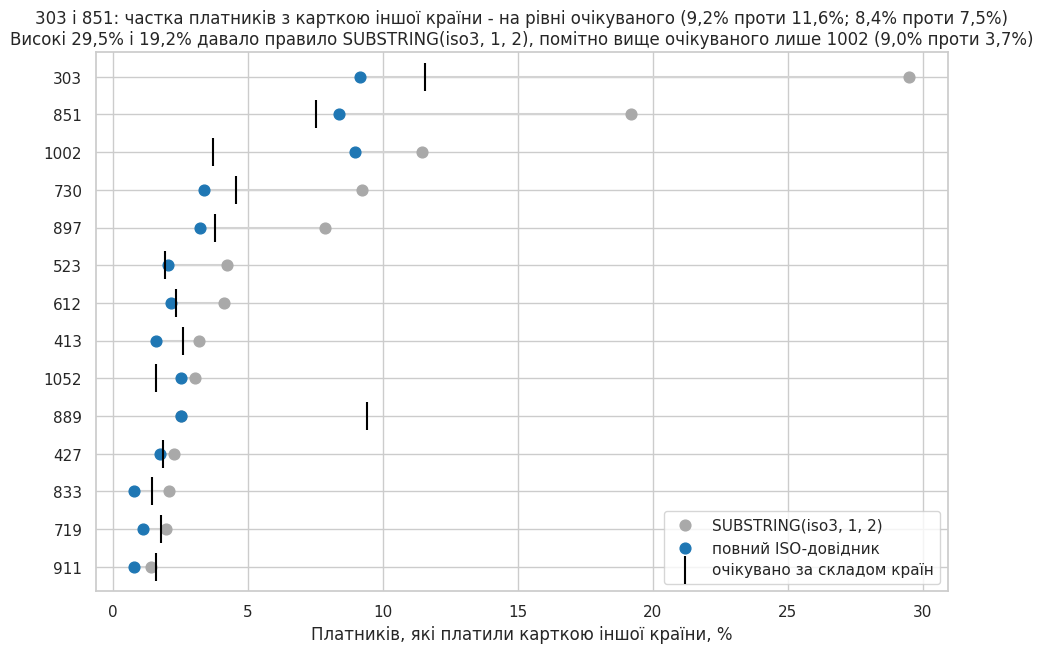

In [81]:
g = geo[geo.network.isin(payout.network)].sort_values('mismatch_old_pct').reset_index(drop=True)
fig, ax = plt.subplots(figsize=(11, 7))
ax.hlines(g.index, g[['mismatch_new_pct', 'mismatch_old_pct']].min(axis=1),
          g[['mismatch_new_pct', 'mismatch_old_pct']].max(axis=1), color='lightgray', zorder=1)
ax.scatter(g.mismatch_old_pct, g.index, color='darkgray', s=60, label='SUBSTRING(iso3, 1, 2)', zorder=3)
ax.scatter(g.mismatch_new_pct, g.index, color='tab:blue', s=60, label='повний ISO-довідник', zorder=3)
ax.scatter(g.expected_pct, g.index, color='black', marker='|', s=400, label='очікувано за складом країн', zorder=4)
ax.set_yticks(g.index)
ax.set_yticklabels(g.network)
ax.set_xlabel('Платників, які платили карткою іншої країни, %')
title = "303 і 851: частка платників з карткою іншої країни - на рівні очікуваного (9,2% проти 11,6%; 8,4% проти 7,5%)\nВисокі 29,5% і 19,2% давало правило SUBSTRING(iso3, 1, 2), помітно вище очікуваного лише 1002 (9,0% проти 3,7%)"
ax.set_title(title)
ax.legend(loc='lower right')
save(fig, '05_geo_mismatch')
plt.show()

In [82]:
# Абсолютні числа за відсотками: скільки платників і chargeback стоїть за високими відсотками в деталізації по країнах вище
net_geo_cb = '303'

if net_geo_cb == '…':
    print('...')
else:
    display(q(f"""
        SELECT r.country,
               COUNT(DISTINCT p.id_user)                                                   AS payers,
               COUNT(*)                                                                    AS success_payments,
               COUNT(p.chargeback_date)                                                    AS cb_payments,
               COUNT(DISTINCT CASE WHEN p.chargeback_date IS NOT NULL THEN p.id_user END) AS cb_users,
               ROUND(100.0 * COUNT(p.chargeback_date) / COUNT(*), 2)                       AS cb_rate_payments_pct
        FROM df_payments p
        JOIN df_registrations r ON p.id_user = r.id_user
        WHERE r.network = '{net_geo_cb}' AND p.status = 'success'
        GROUP BY r.country
        ORDER BY cb_payments DESC, payers DESC
    """))

,country,payers,success_payments,cb_payments,cb_users,cb_rate_payments_pct
0,BR,829,2485,17,16,0.68
1,GR,84,1041,8,2,0.77
2,FR,160,1050,6,6,0.57
3,ES,105,468,5,4,1.07
4,AT,21,306,3,1,0.98
...,...,...,...,...,...,...
58,BD,1,3,0,0,0.00
59,JP,1,1,0,0,0.00
60,BL,1,1,0,0,0.00
61,TH,1,6,0,0,0.00


In [83]:
# TR і SI у 303 - абсолютні числа для висновку
q("""
    SELECT r.country,
           COUNT(DISTINCT p.id_user)   AS payers,
           COUNT(*)                    AS success_payments,
           COUNT(p.chargeback_date)    AS cb_payments
    FROM df_payments p
    JOIN df_registrations r ON p.id_user = r.id_user
    WHERE r.network = '303' AND p.status = 'success' AND r.country IN ('TR', 'SI')
    GROUP BY r.country
""")

,country,payers,success_payments,cb_payments
0,SI,27,97,2
1,TR,14,25,1


### відмови в оплаті

In [84]:
df_payments['status'].unique()

array(['success', 'fail'], dtype=object)

In [85]:
query_decline_rate = """
    SELECT
        network,
        COUNT(*) AS total_payments,
        ROUND(SUM(CASE WHEN status='fail' THEN 1 ELSE 0 END) * 100.0 / COUNT(*), 2) AS decline_rate
    FROM df_payments p
    LEFT JOIN df_registrations r ON p.id_user = r.id_user
    GROUP BY network
    ORDER BY decline_rate DESC
"""
display(duckdb.query(query_decline_rate).df())

,network,total_payments,decline_rate
0,851,10363,68.37
1,911,9434,67.77
2,523,43182,53.91
3,889,17123,51.10
4,303,19377,50.17
5,833,119342,47.21
6,ppc,1173095,44.99
7,organic,441149,41.93
8,612,11157,39.04
9,719,53856,38.39


### відмови проти очікуваного за складом країн і спроби на користувача

In [86]:
# Decline rate: фактичний проти очікуваного за складом країн
decline = q("""
    WITH att AS (
        SELECT r.network, r.traffic_type, r.country,
               CASE WHEN p.status = 'fail' THEN 1 ELSE 0 END AS is_fail
        FROM df_payments p
        JOIN df_registrations r ON p.id_user = r.id_user
    ),
    country_base AS (
        SELECT country, AVG(is_fail) AS base_rate
        FROM att
        WHERE traffic_type = 'ppc'
        GROUP BY country
        HAVING COUNT(*) >= 100
    )
    SELECT att.network,
           COUNT(*)                                                                  AS attempts,
           ROUND(100.0 * AVG(is_fail), 1)                                            AS decline_pct,
           ROUND(100.0 * AVG(b.base_rate), 1)                                        AS expected_pct,
           ROUND(100.0 * (AVG(is_fail) FILTER (WHERE b.base_rate IS NOT NULL)
                          - AVG(b.base_rate)), 1)                                    AS excess_pp,
           ROUND(100.0 * COUNT(b.base_rate) / COUNT(*), 1)                           AS covered_by_baseline_pct
    FROM att
    LEFT JOIN country_base b ON att.country = b.country
    GROUP BY att.network
    ORDER BY excess_pp DESC
""")
display(decline)

# Card testing
attempts = q("""
    WITH u AS (
        SELECT r.network, p.id_user,
               COUNT(*)                                     AS attempts,
               COUNT(*) FILTER (WHERE p.status = 'fail')    AS fails,
               COUNT(*) FILTER (WHERE p.status = 'success') AS successes
        FROM df_payments p
        JOIN df_registrations r ON p.id_user = r.id_user
        GROUP BY r.network, p.id_user
    )
    SELECT network,
           COUNT(*)                                                          AS users_with_attempts,
           ROUND(AVG(attempts), 2)                                           AS avg_attempts,
           ROUND(QUANTILE_CONT(fails, 0.99), 0)                              AS fails_p99,
           ROUND(100.0 * AVG(CASE WHEN fails >= 5 THEN 1 ELSE 0 END), 2)     AS users_5plus_fails_pct,
           ROUND(100.0 * AVG(CASE WHEN successes = 0 THEN 1 ELSE 0 END), 1)  AS only_fails_pct
    FROM u
    GROUP BY network
    ORDER BY users_5plus_fails_pct DESC
""")
display(attempts)

,network,attempts,decline_pct,expected_pct,excess_pp,covered_by_baseline_pct
0,911,9434,67.8,48.6,19.2,100.0
1,851,10363,68.4,49.8,18.8,98.9
2,523,43182,53.9,42.1,11.8,99.9
3,833,119342,47.2,38.7,8.5,99.9
4,719,53856,38.4,38.0,0.4,99.9
5,ppc,1173095,45.0,45.0,0.0,99.8
6,303,19377,50.2,50.6,-0.3,99.0
7,612,11157,39.0,40.3,-1.3,99.9
8,organic,441149,41.9,43.6,-1.9,99.4
9,889,17123,51.1,53.3,-2.2,100.0


,network,users_with_attempts,avg_attempts,fails_p99,users_5plus_fails_pct,only_fails_pct
0,organic,46005,9.59,52.0,15.66,40.0
1,ppc,133177,8.81,50.0,14.88,39.1
2,719,6193,8.70,47.0,13.89,30.9
3,1052,5012,10.28,48.0,13.75,26.3
4,889,2331,7.35,44.0,12.57,40.0
5,897,6881,9.08,43.0,10.73,19.0
6,833,23640,5.05,24.0,10.26,44.9
7,413,10751,6.71,27.0,9.77,18.1
8,1002,8717,7.83,29.0,9.52,16.7
9,427,13655,7.30,26.0,9.43,16.4


#### Висновок: 303 - розбіжність країн пояснює склад трафіку
- **Аномалія.** 9,2% платників 303 платили карткою іншої країни - в 1,7 раза більше, ніж у PPC (5,5%). Net ROAS 2,94 - найнижчий після 612.
- **Перевірка.** Для країн, з яких іде трафік 303, очікувана розбіжність - 11,6%, тож фактичні 9,2% навіть нижчі за норму. Відмови в оплаті 50,2% при очікуваних 50,6%. Chargeback у користувачах 1,93% - нижче PPC (2,49%). Високий відсоток chargeback в окремих країнах стоїть на 1-2 випадках: TR - 1 з 25 платежів, SI - 2 з 97.
- **Висновок.** Ознак крадених карток чи підміни геолокації немає: розбіжність пояснює склад країн.
- **Рішення - норма.** Низька окупність - питання ставки, а не фроду.

#### Висновок: 851 - відмови в оплаті без перебору карток
- **Аномалія.** Відхилено 68,4% спроб оплати - майже на 19 п.п. більше, ніж очікувано за складом країн (49,8%). Розкид кількості сесій (stddev) - один з найнижчих. Так могли б виглядати боти або перебір крадених карток (card testing).
- **Перевірка.** Хто намагався заплатити, робив у середньому 3,83 спроби проти 8,81 у PPC, а 5+ невдалих спроб було у 7,9% проти 14,9%. Chargeback у користувачах 1,11% - найнижчий серед мереж, розбіжність країн 8,4% - на рівні очікуваних 7,5%. Розкид сесій низький, бо самих сесій мало: в середньому 1,2 на людину (графік 06). Відносно середнього розкид навіть вищий, ніж в органіці (22,6 проти 10,5).
- **Висновок.** Люди пробують заплатити раз-два й кидають, а не перебирають картки, і на ботів не схожі. Це аудиторія низької якості: навіть оплачені реєстрації повертаються на 7-й день лише в 1,16% випадків проти 5-6% у більшості CPA-мереж.
- **Рішення - моніторинг.** Мережа окупається на рівні партнерів (net ROAS 4,33 при медіані 4,48), бо ми платимо лише за 24% її реєстрацій. Причина надлишкових відмов невідома, сигнал - decline понад очікуваний > 20 п.п.

## 7. Залученість: кредити, D7, сесії

### кредити на користувача і типи кредитів


In [87]:
query_credits_profile = """
    WITH user_credits AS (
        SELECT id_user, SUM(credits_changed) AS total_credits
        FROM df_credits
        GROUP BY id_user
    )
    SELECT
        r.network,
        COUNT(r.id_user) AS total_users,
        ROUND(COUNT(c.id_user) * 100.0 / COUNT(r.id_user), 2) AS users_with_credits_pct,
        ROUND(AVG(COALESCE(c.total_credits, 0)), 0) AS avg_credits_per_user
    FROM df_registrations r
    LEFT JOIN user_credits c ON r.id_user = c.id_user
    GROUP BY r.network
    HAVING total_users > 1000
    ORDER BY avg_credits_per_user DESC
"""
display(duckdb.query(query_credits_profile).df())

,network,total_users,users_with_credits_pct,avg_credits_per_user
0,1002,108535,6.69,225.0
1,1052,95788,3.86,214.0
2,427,232251,4.92,136.0
3,413,184394,4.77,116.0
4,719,123232,3.47,105.0
5,612,111675,3.47,85.0
6,897,153366,3.63,83.0
7,organic,1156766,2.39,82.0
8,730,137252,4.12,80.0
9,ppc,3117908,2.60,69.0


In [88]:
query_credit_types = """
    WITH user_credit_types AS (
        SELECT
            id_user,
            COUNT(DISTINCT credit_type) AS distinct_types
        FROM df_credits
        GROUP BY id_user
    )
    SELECT
        r.network,
        COUNT(DISTINCT r.id_user) AS total_users,
        COUNT(DISTINCT uc.id_user) AS users_with_credits,
        ROUND(SUM(CASE WHEN uc.distinct_types = 1 THEN 1 ELSE 0 END) * 100.0 / NULLIF(COUNT(DISTINCT uc.id_user), 0), 2) AS single_type_only_pct
    FROM df_registrations r
    LEFT JOIN user_credit_types uc ON r.id_user = uc.id_user
    GROUP BY r.network
    HAVING total_users > 300
    ORDER BY single_type_only_pct DESC
"""
display(duckdb.query(query_credit_types).df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,network,total_users,users_with_credits,single_type_only_pct
0,851,219451,908,6.06
1,523,790549,5189,6.05
2,833,1114202,13031,6.04
3,1052,95788,3693,5.58
4,719,123232,4280,5.49
5,911,267478,950,5.47
6,612,111675,3879,4.61
7,730,137252,5655,4.53
8,organic,1156766,27598,4.50
9,427,232251,11419,4.35


### кредити на платника

Кредити на користувача залежать від конверсії: що більше платників, то більше витрат валюти. Тому порівнюємо витрати на платника.

In [89]:
credits = q("""
    WITH payers AS (SELECT DISTINCT id_user FROM df_payments WHERE status = 'success'),
    cr AS (SELECT id_user, SUM(credits_changed) AS credits FROM df_credits GROUP BY id_user)
    SELECT r.network,
           COUNT(*)                                                  AS users,
           COUNT(pa.id_user)                                         AS payers,
           ROUND(COALESCE(SUM(cr.credits), 0) / COUNT(*), 0)         AS credits_per_user,
           ROUND(SUM(cr.credits) FILTER (WHERE pa.id_user IS NOT NULL)
                 / NULLIF(COUNT(pa.id_user), 0), 0)                  AS credits_per_payer,
           COUNT(cr.id_user) FILTER (WHERE pa.id_user IS NULL)       AS credits_without_success_payment,
           COUNT(pa.id_user) FILTER (WHERE cr.id_user IS NULL)       AS payers_without_credits
    FROM df_registrations r
    LEFT JOIN payers pa ON r.id_user = pa.id_user
    LEFT JOIN cr        ON r.id_user = cr.id_user
    GROUP BY r.network
    ORDER BY credits_per_user DESC
""")
display(credits)

,network,users,payers,credits_per_user,credits_per_payer,credits_without_success_payment,payers_without_credits
0,1002,108535,7262,225.0,3369.0,0,0
1,1052,95788,3693,214.0,5554.0,0,0
2,427,232251,11419,136.0,2773.0,0,0
3,413,184394,8804,116.0,2423.0,0,0
4,719,123232,4280,105.0,3023.0,0,0
5,612,111675,3247,85.0,2600.0,632,0
6,897,153366,5574,83.0,2287.0,0,0
7,organic,1156766,27589,82.0,3427.0,9,0
8,730,137252,5655,80.0,1951.0,0,0
9,ppc,3117908,81055,69.0,2641.0,0,2


#### Висновок
На платника 1002 витрачає майже стільки ж кредитів, скільки органіка: 3 369 проти 3 427. Високі кредити на користувача (225 проти 82 в органіці) пояснює вища конверсія в платника (6,69% проти 2,39%), а не аномальна поведінка.

#### Висновок: 1002 - висока конверсія пояснюється моделлю CPS
- **Аномалія.** Найвища серед мереж конверсія в платника (6,69% проти 2,39% в органіці) і найбільше кредитів на користувача (225 проти 82). Так міг би виглядати мотивований трафік.
- **Перевірка.** 1002 - CPS-мережа: ми платимо переважно за платників (68,7% оплачених реєстрацій - платники, у середньому 382 за реєстрацію), тож партнер і приводить тих, хто платить. На платника 1002 витрачає майже стільки ж кредитів, скільки органіка: 3 369 проти 3 427. Chargeback у користувачах 2,37% - на рівні PPC (2,49%), тож кардингу немає.
- **Висновок.** Висока конверсія - властивість моделі CPS, а платники 1002 поводяться як органічні.
- **Швидкі реєстрації:** За 10-54 с реєструються 7,6% користувачів 1002 - більше лише в 523. Партнер отримує виплату за них так само часто, як за решту (6,0% проти 5,9%), а платять вони в 4,3 раза рідше (1,66% проти 7,10%), тоді як у PPC - лише в 1,5 раза. Проте окремого горба, як у 523, немає: найбільше реєстрацій 1002 припадає на 65-69 с, і надлишок там такий самий, як у 851 (2,11 і 2,10 п.п.). А платять швидкі 1002 так само, як швидкі в PPC (1,66% і 1,76%): розрив створює передусім решта мережі, яка платить майже втричі частіше за PPC (7,10% проти 2,60%), - властивість CPS. Доказ спірний, а на сегмент іде лише 2,7% витрат на 1002 (65 694), тож це привід для моніторингу, а не для переговорів.
- **Рішення - моніторинг.** Лишаються два відхилення: розбіжність країн 9,0% при очікуваних 3,7% (без chargeback це не кардинг) і швидкі реєстрації. Мережа велика (12,0% бюджету CPA, net ROAS 5,03), тому стежимо: сигнал - розбіжність понад очікувану > 6 п.п., chargeback у користувачах > 4% або частка реєстрацій за 10-54 с > 10%.

In [90]:
display(q("""
    WITH payers AS (SELECT DISTINCT id_user FROM df_payments WHERE status = 'success'),
    odd AS (
        SELECT r.network, c.id_user
        FROM (SELECT DISTINCT id_user FROM df_credits) c
        JOIN df_registrations r ON c.id_user = r.id_user
        WHERE c.id_user NOT IN (SELECT id_user FROM payers)
    )
    SELECT odd.network,
           COUNT(DISTINCT odd.id_user)                AS users,
           COUNT(p.id_user)                           AS payment_rows,
           COUNT(*) FILTER (WHERE p.status = 'fail')  AS fail_rows,
           COUNT(p.chargeback_date)                   AS chargeback_rows
    FROM odd
    LEFT JOIN df_payments p ON odd.id_user = p.id_user
    GROUP BY odd.network
    ORDER BY users DESC
"""))

,network,users,payment_rows,fail_rows,chargeback_rows
0,612,632,632,632,0
1,523,223,2,2,0
2,911,60,0,0,0
3,organic,9,2,2,0


### D7 retention

In [91]:
query_retention = """
    WITH max_date AS (
        SELECT MAX(CAST(date_created AS TIMESTAMP)) AS md FROM df_registrations
    ),
    mature_users AS (
        SELECT r.id_user, r.network, CAST(r.date_created AS TIMESTAMP) AS reg_ts
        FROM df_registrations r, max_date
        WHERE CAST(r.date_created AS TIMESTAMP) <= max_date.md - INTERVAL '8 day'
    ),
    day7_flag AS (
        SELECT
            u.id_user,
            u.network,
            MAX(CASE WHEN CAST(a.date_start AS TIMESTAMP) BETWEEN u.reg_ts + INTERVAL '7 day' AND u.reg_ts + INTERVAL '8 day' THEN 1 ELSE 0 END) AS active_day7
        FROM mature_users u
        LEFT JOIN df_activity a ON u.id_user = a.id_user
        GROUP BY u.id_user, u.network
    )
    SELECT
        network,
        COUNT(*) AS total_users,
        ROUND(SUM(active_day7) * 100.0 / COUNT(*), 2) AS day7_retention_pct
    FROM day7_flag
    GROUP BY network
    HAVING total_users > 300
    ORDER BY day7_retention_pct ASC
"""
display(duckdb.query(query_retention).df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,network,total_users,day7_retention_pct
0,851,219074,0.59
1,911,267265,0.65
2,523,759857,1.18
3,303,170226,1.88
4,833,1086892,2.48
5,1052,89926,3.18
6,organic,1107768,3.68
7,1002,104151,4.43
8,897,144977,4.47
9,612,110160,4.66


### D7 окремо для оплачених і неоплачених реєстрацій

D7 рахуємо окремо для реєстрацій, за які ми платили, і для решти.

In [92]:
d7_paid = q("""
    WITH md AS (SELECT MAX(date_created) AS md FROM df_registrations),
    u AS (
        SELECT r.network, r.id_user, r.date_created, r.cost IS NOT NULL AS is_paid
        FROM df_registrations r
        WHERE r.traffic_type = 'cpa'
          AND r.date_created <= (SELECT md FROM md) - INTERVAL 8 DAY
    ),
    d7 AS (
        SELECT u.id_user,
               MAX(CASE WHEN a.date_start BETWEEN u.date_created + INTERVAL 7 DAY
                                              AND u.date_created + INTERVAL 8 DAY THEN 1 ELSE 0 END) AS active_d7
        FROM u
        JOIN df_activity a ON a.id_user = u.id_user
        GROUP BY u.id_user
    )
    SELECT u.network,
           COUNT(*) FILTER (WHERE u.is_paid)                                               AS paid_users,
           ROUND(100.0 * AVG(COALESCE(d7.active_d7, 0)) FILTER (WHERE u.is_paid), 2)       AS d7_paid_pct,
           COUNT(*) FILTER (WHERE NOT u.is_paid)                                           AS unpaid_users,
           ROUND(100.0 * AVG(COALESCE(d7.active_d7, 0)) FILTER (WHERE NOT u.is_paid), 2)   AS d7_unpaid_pct
    FROM u
    LEFT JOIN d7 ON u.id_user = d7.id_user
    GROUP BY u.network
    ORDER BY d7_paid_pct
""")
d7_paid.insert(1, 'model', d7_paid.network.map(model_of))
display(d7_paid)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,network,model,paid_users,d7_paid_pct,unpaid_users,d7_unpaid_pct
0,851,CPA,53225,1.16,165849,0.40
1,911,CPA,51971,1.32,215294,0.49
2,523,CPA,280815,1.83,479042,0.80
3,303,CPA,117418,2.17,52808,1.24
4,833,CPA,373171,3.27,713721,2.07
5,897,CPA,91565,5.09,53412,3.40
6,427,CPA,170188,5.87,49064,1.54
7,413,CPA,135805,5.87,38690,1.20
8,719,CPA,73369,5.90,44287,3.68
9,1052,змішана,12661,6.18,77265,2.69


#### Висновок
Низький D7 у 851, 911 і 523 значною мірою дають реєстрації, за які ми не платимо: D7 неоплачених - 0,40–0,80% проти 1,16–1,83% в оплачених. Але й оплачені реєстрації цих мереж повертаються у 3–5 разів рідше, ніж у більшості CPA-мереж (5–6%).

### тривалість сесій і розкид їх кількості

In [93]:
query_activity_duration = """
    SELECT
        r.network,
        COUNT(a.id_user) AS total_sessions,
        MEDIAN(a.duration) AS median_duration_sec,
        -- Відсоток сесій з нульовою або від'ємною тривалістю
        ROUND(SUM(CASE WHEN a.duration <= 0 THEN 1 ELSE 0 END) * 100.0 / COUNT(a.id_user), 2) AS zero_duration_pct,
        -- Відсоток дуже коротких сесій (< 5 секунд)
        ROUND(SUM(CASE WHEN a.duration < 5 THEN 1 ELSE 0 END) * 100.0 / COUNT(a.id_user), 2) AS micro_session_pct
    FROM df_activity a
    JOIN df_registrations r ON a.id_user = r.id_user
    GROUP BY r.network
    HAVING total_sessions > 1000
    ORDER BY zero_duration_pct DESC, micro_session_pct DESC
"""
display(duckdb.query(query_activity_duration).df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,network,total_sessions,median_duration_sec,zero_duration_pct,micro_session_pct
0,organic,12058481,91.0,0.0,0.0
1,833,3797706,84.0,0.0,0.0
2,413,1601085,99.0,0.0,0.0
3,ppc,32846284,99.0,0.0,0.0
4,1002,1523728,93.0,0.0,0.0
5,897,1745548,78.0,0.0,0.0
6,911,289251,97.0,0.0,0.0
7,851,253947,83.0,0.0,0.0
8,889,616429,108.0,0.0,0.0
9,303,665410,106.0,0.0,0.0


In [94]:
query_behavior_variance = """
    WITH user_behavior AS (
        SELECT
            r.network,
            r.id_user,
            COUNT(a.id_user) AS session_count,
            COALESCE(AVG(a.duration), 0) AS avg_duration
        FROM df_registrations r
        LEFT JOIN df_activity a ON r.id_user = a.id_user
        GROUP BY r.network, r.id_user
    )
    SELECT
        network,
        COUNT(*) AS total_users,
        ROUND(AVG(session_count), 2) AS avg_sessions,
        ROUND(STDDEV(session_count), 2) AS stddev_sessions,
        ROUND(SUM(CASE WHEN session_count = 0 THEN 1 ELSE 0 END) * 100.0 / COUNT(*), 2) AS zero_session_pct
    FROM user_behavior
    GROUP BY network
    HAVING total_users > 300
    ORDER BY stddev_sessions ASC
"""
display(duckdb.query(query_behavior_variance).df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,network,total_users,avg_sessions,stddev_sessions,zero_session_pct
0,911,267478,1.08,13.24,65.58
1,851,219451,1.16,26.11,72.86
2,523,790549,1.87,28.81,54.95
3,833,1114202,3.41,42.08,46.85
4,413,184394,8.68,59.39,38.46
5,303,174637,3.81,61.16,69.79
6,889,62118,9.92,79.81,37.84
7,427,232251,9.33,80.02,39.21
8,719,123232,10.24,82.90,42.04
9,730,137252,10.72,102.70,35.24


### чи розкид сесій незалежний від їх середньої кількості

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,network,avg_sessions,stddev_sessions,cv
0,911,1.08,13.24,12.2
1,851,1.16,26.11,22.6
2,523,1.87,28.81,15.4
3,833,3.41,42.08,12.3
4,413,8.68,59.39,6.8
5,303,3.81,61.16,16.1
6,889,9.92,79.81,8.0
7,427,9.33,80.02,8.6
8,719,10.24,82.90,8.1
9,730,10.72,102.70,9.6


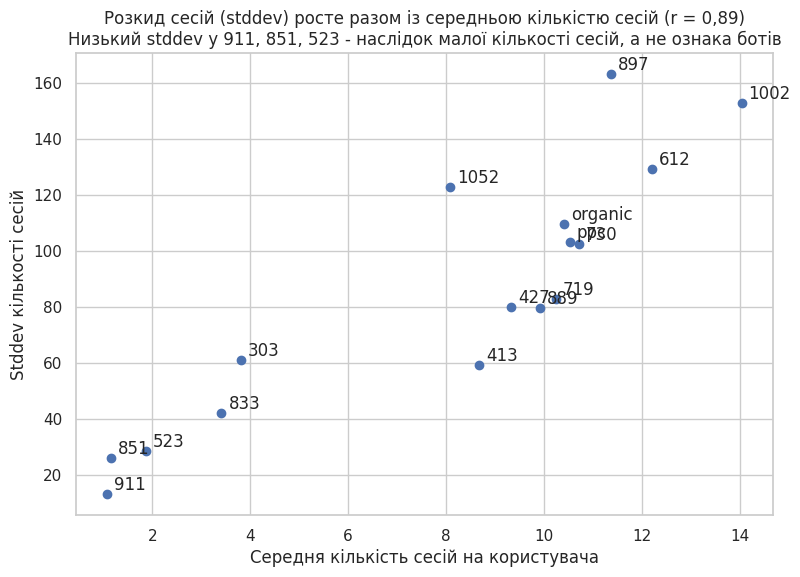

In [95]:
# Чи stddev сесій незалежна від середньої кількості сесій? Якщо точки лягають на пряму - stddev просто повторює рівень залученості.
sess = q("""
    WITH s AS (
        SELECT r.network, r.id_user, COUNT(a.id_user) AS sessions
        FROM df_registrations r
        LEFT JOIN df_activity a ON r.id_user = a.id_user
        GROUP BY r.network, r.id_user
    )
    SELECT network,
           ROUND(AVG(sessions), 2)                     AS avg_sessions,
           ROUND(STDDEV(sessions), 2)                  AS stddev_sessions,
           ROUND(STDDEV(sessions) / AVG(sessions), 1)  AS cv   -- розкид відносно середнього
    FROM s
    GROUP BY network
    ORDER BY stddev_sessions
""")
display(sess)

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(sess.avg_sessions, sess.stddev_sessions)
for _, r in sess.iterrows():
    ax.annotate(r.network, (r.avg_sessions, r.stddev_sessions), xytext=(5, 3), textcoords='offset points')
ax.set_xlabel('Середня кількість сесій на користувача')
ax.set_ylabel('Stddev кількості сесій')
title = "Розкид сесій (stddev) росте разом із середньою кількістю сесій (r = 0,89)\nНизький stddev у 911, 851, 523 - наслідок малої кількості сесій, а не ознака ботів"
ax.set_title(title)
save(fig, '06_sessions_mean_vs_stddev')
plt.show()

In [96]:
sess['avg_sessions'].corr(sess['stddev_sessions']).round(2)

np.float64(0.89)

#### Висновок
Низький розкид сесій (stddev) - не ознака ботів. Stddev росте разом із середньою кількістю сесій (r = 0,89, графік 06): у 911, 851 і 523 в середньому лише 1–2 сесії на людину, тому великого розкиду там бути не може. Чесне порівняння - відносний розкид (stddev / середнє): 851 - 22,6, 523 - 15,4, 911 - 12,2 проти 10,5 в органіці. У ботів, які поводяться однаково, він був би нижчим, а тут вищий. Тому розкид сесій як окремий доказ не використовуємо.

## 8. Економіка і рішення по кожному партнеру

### ROAS

In [97]:
query_roas = """
    WITH network_cost AS (
        SELECT network, SUM(cost) AS total_cost
        FROM df_registrations
        GROUP BY network
    ),
    network_revenue AS (
        SELECT r.network, SUM(p.amount) AS total_revenue
        FROM df_registrations r
        JOIN df_payments p ON r.id_user = p.id_user
        WHERE p.status = 'success'
        GROUP BY r.network
    )
    SELECT
        c.network,
        ROUND(c.total_cost, 2) AS total_cost,
        COALESCE(rv.total_revenue, 0) AS total_revenue,
        ROUND(COALESCE(rv.total_revenue, 0) / NULLIF(c.total_cost, 0), 4) AS roas
    FROM network_cost c
    LEFT JOIN network_revenue rv ON c.network = rv.network
    WHERE c.total_cost > 100
    ORDER BY roas ASC
"""
display(duckdb.query(query_roas).df())

,network,total_cost,total_revenue,roas
0,612,1168206.18,1094085.0,0.9366
1,303,338472.54,997940.0,2.9484
2,730,1442696.19,5591675.0,3.8759
3,413,2731466.84,10883195.0,3.9844
4,833,2912719.18,11759020.0,4.0371
5,851,94133.00,409425.0,4.3494
6,719,1476975.28,6548495.0,4.4337
7,523,840477.72,3832030.0,4.5593
8,427,3322418.29,16070390.0,4.8370
9,ppc,21511213.42,108414370.0,5.0399


### net ROAS, частка бюджету, когорти, рішення

Рішення приймаю за двома осями: чи є фрод і чи окупається мережа.

In [98]:
econ = q("""
    WITH rev AS (
        SELECT id_user,
               SUM(amount)                                                         AS revenue,
               COALESCE(SUM(amount) FILTER (WHERE chargeback_date IS NOT NULL), 0) AS cb_amount
        FROM df_payments
        WHERE status = 'success'
        GROUP BY id_user
    )
    SELECT r.network,
           ANY_VALUE(r.traffic_type)                                                   AS traffic_type,
           COUNT(*)                                                                    AS users,
           ROUND(SUM(r.cost), 0)                                                       AS spend,
           ROUND(COALESCE(SUM(rev.revenue), 0), 0)                                     AS revenue,
           ROUND(COALESCE(SUM(rev.cb_amount), 0), 0)                                   AS cb_amount,
           ROUND(SUM(rev.revenue) / NULLIF(SUM(r.cost), 0), 2)                         AS roas_gross,
           ROUND((SUM(rev.revenue) - SUM(rev.cb_amount)) / NULLIF(SUM(r.cost), 0), 2)  AS roas_net
    FROM df_registrations r
    LEFT JOIN rev ON r.id_user = rev.id_user
    GROUP BY r.network
""")
is_cpa = econ.traffic_type == 'cpa'
econ['share_of_cpa_spend_pct'] = (100 * econ.spend / econ.loc[is_cpa, 'spend'].sum()).where(is_cpa).round(1)
econ.insert(1, 'model', econ.network.map(model_of))
display(econ.sort_values('roas_net'))

,network,model,traffic_type,users,spend,revenue,cb_amount,roas_gross,roas_net,share_of_cpa_spend_pct
7,612,CPS,cpa,111675,1168206.0,1094085.0,104500.0,0.94,0.85,5.7
2,303,CPA,cpa,174637,338473.0,997940.0,4205.0,2.95,2.94,1.7
0,730,CPA,cpa,137252,1442696.0,5591675.0,22875.0,3.88,3.86,7.1
11,413,CPA,cpa,184394,2731467.0,10883195.0,40630.0,3.98,3.97,13.4
9,833,CPA,cpa,1114202,2912719.0,11759020.0,48770.0,4.04,4.02,14.3
15,851,CPA,cpa,219451,94133.0,409425.0,2265.0,4.35,4.33,0.5
6,719,CPA,cpa,123232,1476975.0,6548495.0,22060.0,4.43,4.42,7.2
1,523,CPA,cpa,790549,840478.0,3832030.0,15265.0,4.56,4.54,4.1
4,1052,змішана,cpa,95788,1924382.0,10370555.0,1505315.0,5.39,4.61,9.4
3,427,CPA,cpa,232251,3322418.0,16070390.0,77010.0,4.84,4.81,16.3


#### Висновок
Net ROAS нижче 1 лише в 612 (0,85). Найбільший розрив між gross і net ROAS - у 1052 (5,39 -> 4,61): майже весь chargeback мережі дав один користувач.

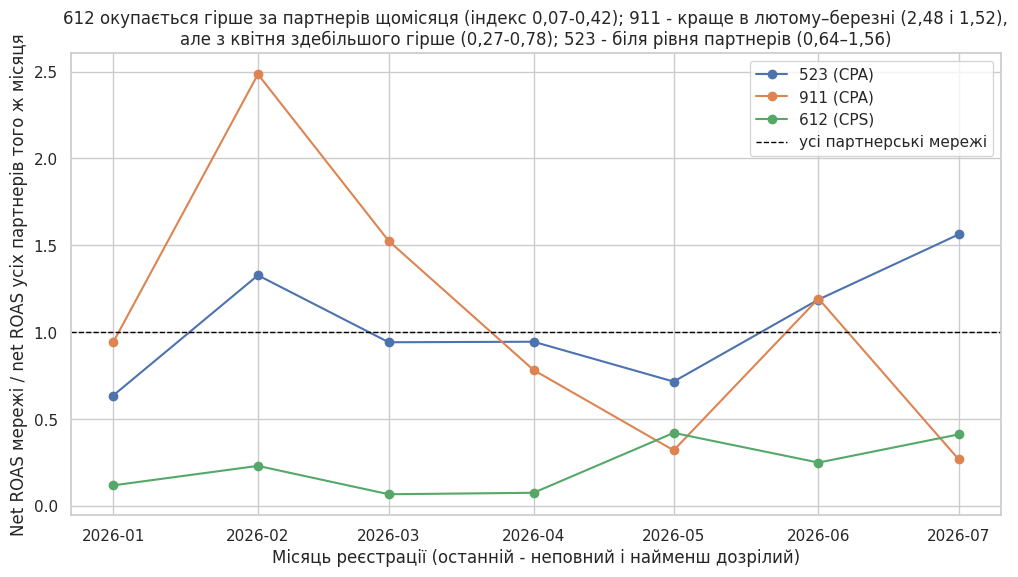

In [99]:
# ROAS по місяцях реєстрації. Пізні когорти мали менше часу заплатити, тому абсолютний ROAS падає в усіх.
# Ділимо на ROAS усіх партнерських мереж за той самий місяць: 1.0 = на рівні партнерів загалом.
# Перший місяць відкидаємо, лише якщо дані починаються не з 1-го числа: неповний місяць дає шумне відношення.
cohort = q("""
    WITH first_full AS (
                SELECT CASE WHEN DATE_TRUNC('day', MIN(date_created)) = DATE_TRUNC('month', MIN(date_created))
                    THEN DATE_TRUNC('month', MIN(date_created))
                    ELSE DATE_TRUNC('month', MIN(date_created)) + INTERVAL 1 MONTH END AS m
        FROM df_registrations
    ),
    rev AS (
        SELECT id_user,
               SUM(amount) - COALESCE(SUM(amount) FILTER (WHERE chargeback_date IS NOT NULL), 0) AS net_revenue
        FROM df_payments
        WHERE status = 'success'
        GROUP BY id_user
    )
    SELECT r.network,
           DATE_TRUNC('month', r.date_created)  AS cohort_month,
           SUM(r.cost)                          AS spend,
           COALESCE(SUM(rev.net_revenue), 0)    AS net_revenue
    FROM df_registrations r
    LEFT JOIN rev ON r.id_user = rev.id_user
    WHERE r.traffic_type = 'cpa'
      AND r.date_created >= (SELECT m FROM first_full)
    GROUP BY r.network, cohort_month
""")
month_total = cohort.groupby('cohort_month')[['spend', 'net_revenue']].sum()
cohort['roas'] = cohort.net_revenue / cohort.spend.replace(0, np.nan)
cohort['roas_all_partners'] = cohort.cohort_month.map(month_total.net_revenue / month_total.spend)
cohort['roas_index'] = cohort.roas / cohort.roas_all_partners

watch = list(dict.fromkeys([net_fast, net_email, cb.network.iloc[0]]))
fig, ax = plt.subplots(figsize=(12, 6))
for n in watch:
    d = cohort[cohort.network == n].sort_values('cohort_month')
    ax.plot(d.cohort_month, d.roas_index, marker='o', label=f'{n} ({model_of(n)})')
ax.axhline(1, color='black', linestyle='--', linewidth=1, label='усі партнерські мережі')
ax.set_ylabel('Net ROAS мережі / net ROAS усіх партнерів того ж місяця')
ax.set_xlabel('Місяць реєстрації (останній - неповний і найменш дозрілий)')
title = "612 окупається гірше за партнерів щомісяця (індекс 0,07-0,42); 911 - краще в лютому–березні (2,48 і 1,52),\nале з квітня здебільшого гірше (0,27-0,78); 523 - біля рівня партнерів (0,64–1,56)"
ax.set_title(title)
ax.legend()
save(fig, '07_roas_by_cohort')
plt.show()

In [100]:
# Індекс окупності по місяцях для мереж з графіка 07 (1.0 = на рівні всіх партнерів того ж місяця)
cohort[cohort.network.isin(['523', '911', '612'])].pivot(index='cohort_month', columns='network', values='roas_index').round(2)

network,523,612,911
cohort_month,,,
2026-01-01,0.64,0.12,0.94
2026-02-01,1.33,0.23,2.48
2026-03-01,0.94,0.07,1.52
2026-04-01,0.95,0.08,0.78
2026-05-01,0.72,0.42,0.32
2026-06-01,1.19,0.25,1.19
2026-07-01,1.56,0.41,0.27


In [101]:
df_registrations.date_created.min(), df_registrations.date_created.max()

(Timestamp('2026-01-01 00:00:02'), Timestamp('2026-07-23 06:59:53'))

#### Висновок
612 окупається гірше за всіх партнерів щомісяця (індекс 0,07-0,42). 911 був вище партнерів у лютому-березні (2,48 і 1,52), а з квітня, коли з'явився tempmail, здебільшого нижче (0,27-0,78, виняток - червень, 1,19), у травні й липні - навіть нижче за 612. 523 тримається біля рівня партнерів (0,64-1,56).

,network,model,spend,share_of_cpa_spend_pct,roas_net,fraud_spend_share_pct,roas_net_without_fraud_spend,verdict
7,612,CPS,1168206.0,5.7,0.85,15.1,1.00,вимкнути
2,303,CPA,338473.0,1.7,2.94,0.0,2.94,норма
0,730,CPA,1442696.0,7.1,3.86,0.0,3.86,норма
11,413,CPA,2731467.0,13.4,3.97,0.0,3.97,норма
9,833,CPA,2912719.0,14.3,4.02,0.0,4.02,норма
15,851,CPA,94133.0,0.5,4.33,0.0,4.33,моніторинг
6,719,CPA,1476975.0,7.2,4.42,0.0,4.42,норма
1,523,CPA,840478.0,4.1,4.54,22.6,5.87,переговори
4,1052,змішана,1924382.0,9.4,4.61,0.0,4.61,моніторинг
3,427,CPA,3322418.0,16.3,4.81,0.0,4.81,норма


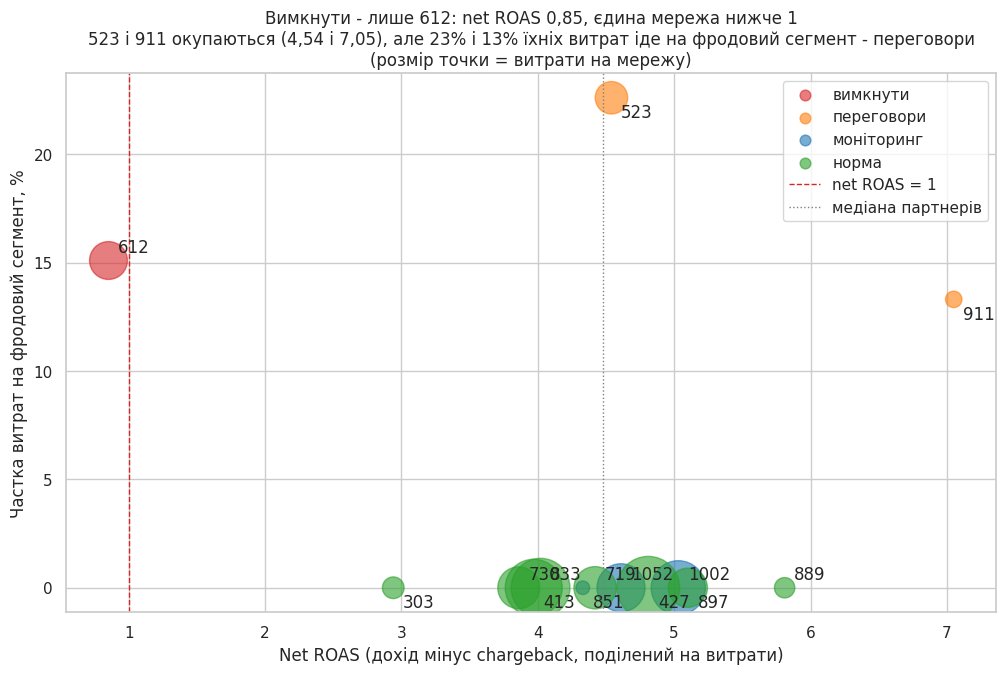

In [102]:
# З висновків розділів 2–7:
# частка витрат на фродовий сегмент = share_of_network_spend_pct із segment_profile
# (для CPS - spend_on_cb_users_pct з таблиці chargeback)
fraud_spend_share = {
    '523': 22.6,   # частка витрат на 523, що припала на вікно 10–54 с (prof_fast)
    '911': 13.3,   # частка витрат на 911, що припала на tempmail.com (prof_email)
    '612': 15.1,   # частка витрат на 612, що припала на користувачів з chargeback (cb)
}
verdict = {
    '612': 'вимкнути', '523': 'переговори', '911': 'переговори', '1052': 'моніторинг',
    '303': 'норма', '851': 'моніторинг', '1002': 'моніторинг', '833': 'норма',
    '413': 'норма', '427': 'норма', '719': 'норма', '730': 'норма', '889': 'норма', '897': 'норма',
}

d = econ[econ.traffic_type == 'cpa'].copy()
d['fraud_spend_share_pct'] = d.network.map(fraud_spend_share).fillna(0)
d['verdict'] = d.network.map(verdict).fillna('без рішення')
# Яким став би net ROAS, якби ми не платили за фродовий сегмент
d['roas_net_without_fraud_spend'] = ((d.revenue - d.cb_amount) / (d.spend * (1 - d.fraud_spend_share_pct / 100))).round(2)
display(d[['network', 'model', 'spend', 'share_of_cpa_spend_pct', 'roas_net', 'fraud_spend_share_pct',
           'roas_net_without_fraud_spend', 'verdict']].sort_values('roas_net'))

if not verdict:
    print('...')
else:
    fig, ax = plt.subplots(figsize=(12, 7))
    verdict_colors = {'вимкнути': 'tab:red', 'переговори': 'tab:orange', 'моніторинг': 'tab:blue',
                      'норма': 'tab:green', 'без рішення': 'lightgray'}
    for v in ['вимкнути', 'переговори', 'моніторинг', 'норма', 'без рішення']:
        grp = d[d.verdict == v]
        if grp.empty:
            continue
        ax.scatter(grp.roas_net, grp.fraud_spend_share_pct, s=40 + 2000 * grp.spend / d.spend.max(), alpha=0.6,
                   label=v, color=verdict_colors.get(v))
    for k, (_, r) in enumerate(d.sort_values('roas_net').iterrows()):
        ax.annotate(r.network, (r.roas_net, r.fraud_spend_share_pct),
                    xytext=(7, 6 if k % 2 == 0 else -14), textcoords='offset points')
    ax.axvline(1, color='tab:red', linestyle='--', linewidth=1, label='net ROAS = 1')
    ax.axvline(d.roas_net.median(), color='gray', linestyle=':', linewidth=1, label='медіана партнерів')
    ax.set_xlabel('Net ROAS (дохід мінус chargeback, поділений на витрати)')
    ax.set_ylabel('Частка витрат на фродовий сегмент, %')
    title = "Вимкнути - лише 612: net ROAS 0,85, єдина мережа нижче 1\n523 і 911 окупаються (4,54 і 7,05), але 23% і 13% їхніх витрат іде на фродовий сегмент - переговори"
    ax.set_title(f'{title}\n(розмір точки = витрати на мережу)')
    leg = ax.legend(loc='upper right')
    for h in getattr(leg, 'legend_handles', None) or getattr(leg, 'legendHandles', []):
        if hasattr(h, 'set_sizes'):
            h.set_sizes([60])
    save(fig, '08_decisions')
    plt.show()

#### Матриця рішень

| Мережа | Модель | Механізм фроду | Докази: 2+ незалежні метрики, графік | Частка фроду у витратах | Net ROAS / частка бюджету CPA | Рішення і сума | Що моніторимо, поріг |
|---|---|---|---|---|---|---|---|
| 612 | CPS | Кардинг: оплати чужими картками, потім chargeback | Chargeback у 20,4% платників проти 2,5% у PPC і 1,3–2,4% в інших CPS (графік 04), gross ROAS 0,94 - єдиний нижче 1 ще до chargeback (графік 07) | 15,1% (176 258) | 0,85 / 5,7% | **Вимкнути**, вимагати повернення 176 258 | Частка платників з chargeback (платежі старші за 60 днів) > 4% |
| 523 | CPA | Клікери: реєстрації, що проходять лендинг за 10–54 с | 22,8% реєстрацій за 10–54 с проти 0,85% у медіанної CPA (графік 02), платять 0,35% проти 0,82% у решти 523 | 22,6% (189 804) | 4,54 / 4,1% | **Переговори**: не платити за реєстрації, швидші за 55 с (189 804 за період) | Частка реєстрацій за 10–54 с на тиждень > 10% (в інших мережах до 7,6%) |
| 911 | CPA | Мотивований трафік: реєстрації на тимчасову пошту tempmail.com | tempmail - 34,4% реєстрацій, ~50% щотижня з 30.03, у PPC та інших CPA - 0 (графік 03), платять 0,07% проти 0,51% у решти 911 | 13,3% (22 162) | 7,05 (з квітня здебільшого нижче партнерів) / 0,8% | **Переговори**: не платити за реєстрації з тимчасових пошт (22 162 за період), якщо за 4 тижні частка не впаде - вимкнути | Частка реєстрацій з тимчасових доменів на тиждень > 2% (в інших мережах - 0) |
| 1052 | Змішана | Не фрод мережі: 97% грошей chargeback дав один користувач | Chargeback у грошах 21,2% і в платежах 5,4%, але в користувачах 2,3% - нижче PPC (графік 04), без цього користувача - ≈0,5%, як в інших мережах | - (на користувачів з chargeback - 0,8%) | 4,61 (gross 5,39) / 9,4% | **Моніторинг**, користувача заблокувати, обмежити кількість платежів на користувача | Chargeback у грошах > 1,2% (3× PPC) при користувачах ≤ 2,5% -> перевірка топ-користувачів |
| 303 | CPA | Немає: розбіжність країн пояснює склад трафіку | Розбіжність 9,2% при очікуваних 11,6% (графік 05), decline 50,2% ≈ очікуваним 50,6%, chargeback у користувачах 1,9% - нижче PPC | 0 | 2,94 / 1,7% | **Норма** (низька окупність - питання ставки, а не фроду) | - |
| 851 | CPA | Немає: відмови в оплаті без перебору карток і без ботів | 3,8 спроби оплати на користувача проти 8,8 у PPC, розбіжність країн 8,4% ≈ очікуваним 7,5% (графік 05), низький розкид сесій - наслідок малої кількості сесій (графік 06) | 0 | 4,33 / 0,5% | **Моніторинг**: decline на 18,8 п.п. вищий за очікуваний | Decline понад очікуваний за складом країн > 20 п.п. |
| 1002 | CPS | Немає: висока конверсія - властивість моделі CPS | Кредити на платника 3 369 ≈ органіка 3 427, chargeback у користувачах 2,4% ≈ PPC | 0 | 5,03 / 12,0% | **Моніторинг**: розбіжність країн на 5 п.п. вища за очікувану, без chargeback | Розбіжність понад очікувану > 6 п.п. або chargeback у користувачах > 4% або частка реєстрацій за 10-54 с > 10% |
| 833 | CPA | Немає: 66% реєстрацій без виплати, як і в інших CPA | Payout rate 34% - як у 523, chargeback у користувачах 1,8% - нижче PPC | 0 | 4,02 / 14,3% | **Норма** | - |
| 413, 427, 719, 730, 889, 897 | CPA (889 - CPS) | Немає | Метрики в межах норми | 0 | 3,86–5,81 / 51,6% разом | **Норма** | - |

## 9. Дані для дашборда Tableau

### перша вітрина по мережах і тижневі тренди
Розбіжність країн у цій вітрині рахується за тим самим мапінгом 15 країн, тому завищена (303 - 20,2%, 851 - 18,9%, точні числа - у розділі 6). Дашборд бере з цього блоку лише тижневі тренди, а метрики мереж - з вітрини нижче.

In [103]:


query_datamart_summary = """
    WITH
    base_regs AS (
        SELECT
            network,
            COUNT(id_user) AS total_users,
            SUM(CASE WHEN device_OS = 'unknown' THEN 1 ELSE 0 END) * 100.0 / COUNT(id_user) AS unknown_os_pct
        FROM df_registrations
        GROUP BY network
    ),

    country_mapping AS (
        SELECT * FROM (VALUES
            ('US', 'USA'), ('GB', 'GBR'), ('AU', 'AUS'), ('CA', 'CAN'),
            ('BR', 'BRA'), ('MX', 'MEX'), ('IT', 'ITA'), ('ES', 'ESP'),
            ('FR', 'FRA'), ('ZA', 'ZAF'), ('NZ', 'NZL'), ('CL', 'CHL'),
            ('DE', 'DEU'), ('AR', 'ARG'), ('IL', 'ISR')
        ) AS t(iso2, iso3)
    ),

    payments_agg AS (
        SELECT
            r.network,
            SUM(CASE WHEN p.status = 'fail' THEN 1 ELSE 0 END) * 100.0 / NULLIF(COUNT(p.id_user), 0) AS decline_rate,
            SUM(CASE WHEN p.chargeback_date IS NOT NULL THEN 1 ELSE 0 END) * 100.0 / NULLIF(SUM(CASE WHEN p.status = 'success' THEN 1 ELSE 0 END), 0) AS chargeback_rate,
            COUNT(DISTINCT CASE
                WHEN p.status='success'
                 AND ((m.iso3 IS NOT NULL AND p.country_payment != m.iso3)
                   OR (m.iso3 IS NULL AND SUBSTRING(p.country_payment,1,2) != r.country))
                THEN p.id_user END) * 100.0
                / NULLIF(COUNT(DISTINCT CASE WHEN p.status='success' THEN p.id_user END), 0) AS geo_mismatch_pct
        FROM df_registrations r
        LEFT JOIN df_payments p ON r.id_user = p.id_user
        LEFT JOIN country_mapping m ON r.country = m.iso2
        GROUP BY r.network
    ),

    user_sessions AS (
        SELECT r.network, r.id_user, COUNT(a.date_start) AS session_count
        FROM df_registrations r
        LEFT JOIN df_activity a ON r.id_user = a.id_user
        GROUP BY r.network, r.id_user
    ),
    sessions_agg AS (
        SELECT network, AVG(session_count) AS avg_sessions, STDDEV(session_count) AS stddev_sessions
        FROM user_sessions
        GROUP BY network
    ),

    max_date AS (SELECT MAX(CAST(date_created AS TIMESTAMP)) AS md FROM df_registrations),
    mature_users AS (
        SELECT r.id_user, r.network, CAST(r.date_created AS TIMESTAMP) AS reg_ts
        FROM df_registrations r, max_date
        WHERE CAST(r.date_created AS TIMESTAMP) <= max_date.md - INTERVAL '8 day'
    ),
    retention_agg AS (
        SELECT
            u.network,
            COUNT(DISTINCT CASE
                WHEN CAST(a.date_start AS TIMESTAMP) BETWEEN u.reg_ts + INTERVAL '7 day' AND u.reg_ts + INTERVAL '8 day'
                THEN u.id_user END) * 100.0 / COUNT(DISTINCT u.id_user) AS day7_retention_pct
        FROM mature_users u
        LEFT JOIN df_activity a ON u.id_user = a.id_user
        GROUP BY u.network
    ),

    user_credits AS (
        SELECT r.network, r.id_user, SUM(c.credits_changed) AS total_credits
        FROM df_registrations r
        LEFT JOIN df_credits c ON r.id_user = c.id_user
        GROUP BY r.network, r.id_user
    ),
    credits_agg AS (
        SELECT network, AVG(COALESCE(total_credits, 0)) AS avg_credits_per_user
        FROM user_credits
        GROUP BY network
    )

    SELECT
        b.network, b.total_users,
        ROUND(b.unknown_os_pct, 2) AS unknown_os_pct,
        ROUND(p.decline_rate, 2) AS decline_rate,
        ROUND(p.chargeback_rate, 2) AS chargeback_rate,
        ROUND(p.geo_mismatch_pct, 2) AS geo_mismatch_pct,
        ROUND(s.avg_sessions, 2) AS avg_sessions,
        ROUND(s.stddev_sessions, 2) AS stddev_sessions,
        ROUND(r.day7_retention_pct, 2) AS day7_retention_pct,
        ROUND(c.avg_credits_per_user, 0) AS avg_credits_per_user,
        ROUND(r.day7_retention_pct / NULLIF(p.decline_rate, 0), 4) AS early_quality_score
    FROM base_regs b
    LEFT JOIN payments_agg p ON b.network = p.network
    LEFT JOIN sessions_agg s ON b.network = s.network
    LEFT JOIN retention_agg r ON b.network = r.network
    LEFT JOIN credits_agg c ON b.network = c.network
    WHERE b.total_users > 1000
    ORDER BY total_users DESC
"""

df_datamart_summary = duckdb.query(query_datamart_summary).df()

df_datamart_summary.to_csv('tableau_network_summary.csv', index=False)

display(df_datamart_summary[['network', 'geo_mismatch_pct']].head(10))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,network,geo_mismatch_pct
0,ppc,9.95
1,organic,11.22
2,833,2.08
3,523,4.08
4,911,0.93
5,427,2.25
6,851,18.94
7,413,3.13
8,303,20.19
9,897,7.73


In [104]:
query_datamart_trends = """
    SELECT
        network,
        DATE_TRUNC('week', CAST(date_created AS TIMESTAMP)) AS reg_week,
        COUNT(id_user) AS weekly_regs
    FROM df_registrations
    GROUP BY network, DATE_TRUNC('week', CAST(date_created AS TIMESTAMP))
    ORDER BY reg_week, weekly_regs DESC
"""

df_datamart_trends = duckdb.query(query_datamart_trends).df()

df_datamart_trends.to_csv('tableau_network_trends.csv', index=False)


### вітрина по мережах для дашборда

In [105]:
# Таблиця для Tableau: одна строка на мережу, усі метрики поруч
domain_share = q(f"""
    SELECT network, 100.0 * AVG(CASE WHEN LOWER(SPLIT_PART(email, '@', 2)) = '{domain}' THEN 1 ELSE 0 END) AS share
    FROM df_registrations
    GROUP BY network
""").set_index('network').share

summary = (econ[['network', 'model', 'traffic_type', 'users', 'spend', 'share_of_cpa_spend_pct', 'roas_gross', 'roas_net']]
    .merge(payout[['network', 'paid_share_pct', 'payers_among_paid_pct', 'avg_cost_per_paid_user']], on='network', how='left')
    .merge(cb[['network', 'cb_rate_users_pct', 'cb_rate_payments_pct', 'cb_rate_money_pct', 'median_days_to_cb']],
           on='network', how='left')
    .merge(geo[['network', 'mismatch_new_pct', 'expected_pct', 'excess_pp']]
           .rename(columns={'expected_pct': 'mismatch_expected_pct', 'excess_pp': 'mismatch_excess_pp'}),
           on='network', how='left')
    .merge(decline[['network', 'decline_pct', 'expected_pct', 'excess_pp']]
           .rename(columns={'expected_pct': 'decline_expected_pct', 'excess_pp': 'decline_excess_pp'}),
           on='network', how='left')
    .merge(credits[['network', 'credits_per_payer']], on='network', how='left'))
summary['fast_reg_share_pct'] = summary.network.map(in_window).round(2)       # частка у вікні піку з блоку 3 (лише CPA)
summary['temp_domain_share_pct'] = summary.network.map(domain_share).round(2)  # частка домену з блоку 4

summary.to_csv(f'{DATA_DIR}/tableau_network_summary_v2.csv', index=False)
print(f'Збережено {DATA_DIR}/tableau_network_summary_v2.csv; temp_domain_share_pct = частка {domain}, '
      f'fast_reg_share_pct = частка реєстрацій за {fast_from}–{fast_to} с')
display(summary)

Збережено /content/drive/MyDrive/Case 3/tableau_network_summary_v2.csv; temp_domain_share_pct = частка tempmail.com, fast_reg_share_pct = частка реєстрацій за 10–54 с


,network,model,traffic_type,users,spend,share_of_cpa_spend_pct,roas_gross,roas_net,paid_share_pct,payers_among_paid_pct,avg_cost_per_paid_user,cb_rate_users_pct,cb_rate_payments_pct,cb_rate_money_pct,median_days_to_cb,mismatch_new_pct,mismatch_expected_pct,mismatch_excess_pp,decline_pct,decline_expected_pct,decline_excess_pp,credits_per_payer,fast_reg_share_pct,temp_domain_share_pct
0,730,CPA,cpa,137252,1442696.0,7.1,3.88,3.86,72.00,4.86,14.60,2.02,0.44,0.39,38.0,3.38,4.55,-1.42,36.3,42.0,-5.7,1951.0,0.28,0.00
1,523,CPA,cpa,790549,840478.0,4.1,4.56,4.54,36.70,1.08,2.90,1.32,0.44,0.40,33.0,2.05,1.92,0.08,53.9,42.1,11.8,1317.0,22.81,0.00
2,303,CPA,cpa,174637,338473.0,1.7,2.95,2.94,68.71,1.53,2.82,1.93,0.60,0.46,35.0,9.17,11.57,-3.13,50.2,50.6,-0.3,890.0,0.16,0.00
3,427,CPA,cpa,232251,3322418.0,16.3,4.84,4.81,77.41,5.97,18.48,2.05,0.45,0.47,35.0,1.73,1.86,-0.26,30.9,39.5,-8.6,2773.0,0.27,0.00
4,1052,змішана,cpa,95788,1924382.0,9.4,5.39,4.61,13.38,19.89,150.11,2.34,5.40,21.24,23.0,2.52,1.61,0.80,36.3,39.2,-2.9,5554.0,2.60,0.00
5,889,CPS,cpa,62118,291124.0,1.4,5.82,5.81,1.68,100.00,278.85,1.30,0.25,0.18,38.0,2.53,9.41,-6.95,51.1,53.3,-2.2,2407.0,0.28,0.00
6,719,CPA,cpa,123232,1476975.0,7.2,4.43,4.42,62.61,4.94,19.14,2.36,0.40,0.28,34.0,1.10,1.77,-0.78,38.4,38.0,0.4,3023.0,0.67,0.00
7,612,CPS,cpa,111675,1168206.0,5.7,0.94,0.85,2.08,83.52,502.67,20.37,14.73,12.07,40.0,2.14,2.34,-0.26,39.0,40.3,-1.3,2600.0,1.69,0.00
8,ppc,ppc,ppc,3117908,21511213.0,NaN,5.04,5.02,NaN,NaN,NaN,2.49,0.45,0.41,34.0,5.51,5.02,0.00,45.0,45.0,0.0,2641.0,NaN,0.00
9,833,CPA,cpa,1114202,2912719.0,14.3,4.04,4.02,34.24,1.52,7.63,1.84,0.46,0.39,40.0,0.79,1.46,-0.71,47.2,38.7,8.5,1777.0,3.57,0.00
